# Kidney Perturbation Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 28.01.2026
- Date of Last Modification: 01.02.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries

In [72]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import os
import pickle
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scanpy as sc
import scipy.sparse as sp
import torch
from datasets import load_from_disk

#from app.count_decoder import apply_count_decoder
from app.infer import embed_dataset, harmonize_tokenize_embed_pipeline, perturb_dataset
from nichejepa.preprocessors import construct_neighbor_graph

/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Could not import squidpy...
Could not import squidpy...


## 1.2 Define Config/Params

In [3]:
# Define paths
#model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11012026_190057_836' # cross-tissue model
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614' # benchmarking model
gene_ensembl_map_file_path = '/nfs/team361/sb75/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl'
kidney_perturbation_folder_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation'
cache_directory_path = f'{kidney_perturbation_folder_path}/cache'
results_directory_path = f'{kidney_perturbation_folder_path}/results'
tokenized_data_directory_path = f'{kidney_perturbation_folder_path}/tokenized_data'

In [4]:
cell_type_key = "scANVI_pred"
niche_key = "NEMO_neighborhood_annotation"
batch_key = 'Study_slice_id'

emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

## 1.3 Run Notebook Setup

In [5]:
torch.set_printoptions(threshold=float('inf'))

In [6]:
os.makedirs(tokenized_data_directory_path, exist_ok=True)
os.makedirs(f'{results_directory_path}/figures', exist_ok=True)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{results_directory_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [10]:
def cosine_sim_per_row(A, B, eps=1e-12):
    """
    Row-wise cosine similarity between A and B (shape: [n, d]).
    Handles zero-norm rows safely via eps.
    """
    A = np.asarray(A)
    B = np.asarray(B)

    A_norm = np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = np.linalg.norm(B, axis=1, keepdims=True)

    A_unit = A / np.maximum(A_norm, eps)
    B_unit = B / np.maximum(B_norm, eps)

    return np.sum(A_unit * B_unit, axis=1)

In [56]:
def analyze_embedding_cos_sims(
    adata,
    pairs=None,
    bins=50,
    show=True,
    save_dir=None,
    prefix="",
    eps=1e-12,
    ignore_zeros=False,
):
    """
    Compute row-wise cosine similarities for multiple (A_key, B_key) pairs in adata.obsm,
    print mean/min, and optionally plot + save histograms.

    Parameters
    ----------
    ignore_zeros : bool
        If True, compute mean/min over nonzero cosine similarities only.

    Returns
    -------
    results : dict[str, np.ndarray]
        Mapping from name -> cosine similarity vector (length n_obs).
    summary : dict[str, dict[str, float]]
        Mapping from name -> {"mean": ..., "min": ...}
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb"),
        ]

    results = {}
    summary = {}

    for A_key, B_key, name in pairs:
        A = adata.obsm[A_key]
        B = adata.obsm[B_key]

        sims = cosine_sim_per_row(A, B, eps=eps)

        if ignore_zeros:
            nz = sims != 0
            if np.any(nz):
                mean_v = float(np.mean(sims[nz]))
                min_v = float(np.min(sims[nz]))
            else:
                mean_v = float("nan")
                min_v = float("nan")
        else:
            mean_v = float(np.mean(sims))
            min_v = float(np.min(sims))

        results[name] = sims
        summary[name] = {"mean": mean_v, "min": min_v}

        suffix = " (nonzero)" if ignore_zeros else ""
        print(f"{name}{suffix}: mean={mean_v:.6f}  min={min_v:.6f}")

        plt.figure()
        plt.hist(sims, bins=bins)
        plt.title(f"{prefix}{name} cosine similarity")
        plt.xlabel("cosine similarity")
        plt.ylabel("count")
        plt.tight_layout()

        if save_dir is not None:
            fname = f"{prefix}{name}_cos_sim_hist.png" if prefix else f"{name}_cos_sim_hist.png"
            plt.savefig(f"{save_dir.rstrip('/')}/{fname}", dpi=200)

        if show:
            plt.show()
        else:
            plt.close()

    return results, summary

In [58]:
def summarize_cosine_sim_by_label(
    adata,
    label_key,
    labels=None,
    pairs=None,
    agg="mean",
    sort_by=None,
    ascending=True,
    eps=1e-12,
    ignore_zeros=False,
):
    """
    Compute cosine similarity (row-wise) between embedding pairs in adata.obsm,
    aggregate per label in adata.obs[label_key], and return a sorted DataFrame.

    Parameters
    ----------
    ignore_zeros : bool
        If True, aggregate only over nonzero cosine similarities.
    """
    if pairs is None:
        pairs = [
            ("cell_emb", "cell_emb_perturb_case1", "cell_emb_cos_sim"),
            ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb_cos_sim"),
            ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb_cos_sim"),
        ]

    if labels is None:
        labels = sorted(pd.unique(adata.obs[label_key]))

    if isinstance(agg, str):
        agg_name = agg.lower()
        if agg_name == "min":
            agg_fn = np.min
        elif agg_name == "mean":
            agg_fn = np.mean
        elif agg_name == "median":
            agg_fn = np.median
        else:
            raise ValueError("agg must be 'min', 'mean', 'median', or a callable")
    elif callable(agg):
        agg_fn = agg
    else:
        raise ValueError("agg must be 'min', 'mean', 'median', or a callable")

    rows = []
    for label in labels:
        adata_sub = adata[adata.obs[label_key] == label]

        row = {
            "label": label,
            "n_cells": int(adata_sub.n_obs),
        }

        for A_key, B_key, out_col in pairs:
            sims = cosine_sim_per_row(
                adata_sub.obsm[A_key],
                adata_sub.obsm[B_key],
                eps=eps,
            )

            if ignore_zeros:
                sims = sims[sims != 0]

            if sims.size == 0:
                row[out_col] = float("nan")
            else:
                row[out_col] = float(agg_fn(sims))

        rows.append(row)

    df = pd.DataFrame(rows)

    if sort_by is not None:
        df = df.sort_values(by=sort_by, ascending=ascending).reset_index(drop=True)

    return df


In [13]:
def plot_perturbation_counts(
    dataset,
    flag_prefix="pert_flag_idx_",
    count_column="perturbation_count",
    batch_size=50_000,
    num_proc=None,
    add_column=True,
):
    """
    Count how many perturbations affect each cell in a Hugging Face Dataset
    and plot a bar chart of the counts.

    Parameters
    ----------
    dataset : datasets.Dataset
        Hugging Face dataset with perturbation flag columns.
    flag_prefix : str
        Prefix of perturbation flag columns.
    count_column : str
        Name of the output column containing per-cell perturbation counts.
    batch_size : int
        Batch size for dataset.map.
    num_proc : int or None
        Number of processes for parallel map.
    add_column : bool
        Whether to add the count column back to the dataset.

    Returns
    -------
    dataset : datasets.Dataset
        Dataset with added count column (if add_column=True).
    counts : np.ndarray
        Array of per-cell perturbation counts.
    """

    # 1) find perturbation flag columns
    flag_cols = [c for c in dataset.column_names if c.startswith(flag_prefix)]
    if not flag_cols:
        raise ValueError(f"No columns found starting with '{flag_prefix}'")

    # 2) compute per-cell counts
    def add_counts(batch):
        flags = np.stack(
            [np.asarray(batch[c], dtype=np.bool_) for c in flag_cols],
            axis=1,
        )
        batch[count_column] = flags.sum(axis=1).astype(np.int32)
        return batch

    dataset_out = dataset
    if add_column:
        dataset_out = dataset.map(
            add_counts,
            batched=True,
            batch_size=batch_size,
            num_proc=num_proc,
        )

    # 3) collect counts
    if add_column:
        counts = np.asarray(dataset_out[count_column], dtype=np.int32)
    else:
        # compute counts without modifying dataset
        counts = np.concatenate(
            dataset.map(
                add_counts,
                batched=True,
                batch_size=batch_size,
                num_proc=num_proc,
                remove_columns=dataset.column_names,
            )[count_column]
        )

    # 4) plot bar chart
    values, frequencies = np.unique(counts, return_counts=True)

    plt.figure()
    plt.bar(values, frequencies)
    plt.xlabel("Number of perturbations affecting the cell")
    plt.ylabel("Number of cells")
    plt.title("Perturbation count per cell")
    plt.xticks(values)
    plt.tight_layout()
    plt.show()

    return dataset_out, counts

In [14]:
def plot_cells_per_perturbation(
    dataset,
    flag_prefix="pert_flag_idx_",
    batch_size=50_000,
):
    """
    Plot how many cells are affected by each perturbation.

    X-axis: perturbation index
    Y-axis: number of affected cells
    """

    # 1) find perturbation flag columns (keep order!)
    flag_cols = sorted(
        [c for c in dataset.column_names if c.startswith(flag_prefix)],
        key=lambda x: int(x.split("_")[-1]),
    )

    if not flag_cols:
        raise ValueError(f"No columns found starting with '{flag_prefix}'")

    n_flags = len(flag_cols)
    counts = np.zeros(n_flags, dtype=np.int64)

    # 2) iterate in batches (streaming-friendly, no dataset copy)
    for batch in dataset.iter(batch_size=batch_size):
        flags = np.stack(
            [np.asarray(batch[c], dtype=np.bool_) for c in flag_cols],
            axis=1,
        )
        counts += flags.sum(axis=0)

    # 3) plot
    x = np.arange(n_flags)

    plt.figure()
    plt.bar(x, counts)
    plt.xlabel("Perturbation index")
    plt.ylabel("Number of affected cells")
    plt.title("Cells affected per perturbation")
    plt.xticks(x)
    plt.tight_layout()
    plt.show()

    return counts

# 2. Analysis

## 2.1 Load Data

In [ ]:
# Load original raw data
adata = sc.read_h5ad(
    "/nfs/team361/dj17/NEMO_DJ/KidneyToxicity/NEMO_UpdatedTokenisationandEmbedding_November22nd25/Labeltransfer/forshare/nemokidneyxeniumatlas_annotated.h5ad")
adata

In [ ]:
# Check columns
adata.obs.head(1)

In [ ]:
# List samples
# CV*** -> pre-treatment
# DI*** -> post-treatment
adata.obs[['Study_slice_id', 'Data_source']].drop_duplicates()

In [ ]:
# Compute sample-wise neighbor graph, concatenate, and store in adata.obsp['spatial_connectivities']
adata = construct_neighbor_graph(
    adata,
    n_neighs=10,
    radius=None,
    delaunay=False,
    include_self_loop=False,
    compute_neighbor_counts=False,
    batch_key=batch_key
)

# Compute raw neighborhood counts
adata.layers['counts_neighborhood'] = (
    adata.obsp['spatial_connectivities'].T @ adata.layers['counts'])
print(adata.layers['counts_neighborhood'][:30].toarray())
adata.layers['counts_neighborhood'] += adata.layers['counts'] # add counts from the index cell
print(adata.layers['counts_neighborhood'][:30].toarray())

# Compute lognorm neighborhood counts (performing same normalization as on raw counts)
adata.X = adata.layers["counts_neighborhood"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm_neighborhood"] = adata.X.copy()
adata.X = adata.layers["lognorm"].copy()

In [ ]:
# Validate that everything is ok
print(adata.obsp['spatial_connectivities'].sum(1))
n = 30
print(adata.layers['counts_neighborhood'][:30].toarray())
print(adata.layers['lognorm_neighborhood'][:30].toarray())
print(adata.layers['counts'][:30].toarray())
print(adata.layers['lognorm'][:30].toarray())
print(adata.X[:30].toarray())

In [ ]:
# Add ensembl IDs to AnnData object
with open(gene_ensembl_map_file_path, "rb") as f:
    gene_ensembl_map_dict = pickle.load(f)

gene_names = [gene_name for gene_name in adata.var_names.tolist()]
adata.var.index = gene_names

harmonized_gene_names = []
matching_ensembl_ids = []
for gene_name in gene_names:
    if gene_name in gene_ensembl_map_dict.keys():
        harmonized_gene_names.append(gene_name)
        matching_ensembl_ids.append(gene_ensembl_map_dict[gene_name])

adata.var['ensembl_id'] = matching_ensembl_ids
adata.var

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

## 2.2 Compute Differential Genes Between Pre- and Post-treatment Conditions

Check https://docs.google.com/spreadsheets/d/1i6p3QRTE5Lh32AejWE6Xg2Sye6p3yP7vDdrCMDbLj_I/edit?gid=1921994032#gid=1921994032 for perturbation cases to be tested.

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.1 Perturbation Case 1

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI12_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI12-KID-0-FT-4"), "DI12_vs_CV"] = "DI12"
adata.obs.loc[sid.str.startswith("CV"), "DI12_vs_CV"] = "CV"

adata.obs["DI12_vs_CV"] = adata.obs["DI12_vs_CV"].astype("category")
adata.obs["DI12_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI12_vs_CV",
    groups=["DI12"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case1_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI12", key="rank_genes_groups_case1_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI12 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI12_vs_CV"].isin(["DI12", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI12/CV cells)", "n_DI12": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI12_vs_CV"].value_counts()
    n_di12 = int(counts.get("DI12", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di12 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI12": n_di12,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case1_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI12_vs_CV",
        groups=["DI12"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI12", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case1_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI12": n_di12,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case1_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.2 Perturbation Case 2

In [ ]:
# Load processed AnnData
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
sid = adata.obs["Study_slice_id"].astype(str)

adata.obs["DI10_vs_CV"] = np.nan
adata.obs.loc[sid.eq("DI10-KID-0-FT-5"), "DI10_vs_CV"] = "DI10"
adata.obs.loc[sid.str.startswith("CV"), "DI10_vs_CV"] = "CV"

adata.obs["DI10_vs_CV"] = adata.obs["DI10_vs_CV"].astype("category")
adata.obs["DI10_vs_CV"].value_counts(dropna=False)

In [ ]:
# Compute differential genes for cell counts (across all cells -> global)
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_cell_counts",
)

# Retrieve differential genes for cell counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_cell_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_cell_counts.csv")

In [ ]:
# Compute differential genes for cell counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_cell_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for cell counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_cell_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_cell_counts_summary_by_niche"]

In [ ]:
# Compute differential genes for neighborhood counts (across all cells -> global)
adata.X = adata.layers['lognorm_neighborhood'].copy()
sc.tl.rank_genes_groups(
    adata,
    groupby="DI10_vs_CV",
    groups=["DI10"],
    reference="CV",
    method="wilcoxon",
    pts=True,
    use_raw=False,
    key_added="rank_genes_groups_case2_global_pre_post_neighborhood_counts",
)

# Retrieve differential genes for neighborhood counts
n = 50
diff_genes_df = sc.get.rank_genes_groups_df(adata, group="DI10", key="rank_genes_groups_case2_global_pre_post_neighborhood_counts")
diff_genes_df_top = diff_genes_df.head(n)
diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
display(diff_genes_df_top)
diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_global_pre_post_neighborhood_counts.csv")

In [ ]:
# Compute differential genes for neighborhood counts (across each niche)
# Loop over niches and run DE within each
min_cells_per_group = 20

summary_rows = []

# Get categories (handles categorical + non-categorical)
cats = adata.obs[niche_key].astype("category").cat.categories

for cat in cats:
    # Cells in this niche AND in either DI10 or CV
    mask = (adata.obs[niche_key] == cat) & (adata.obs["DI10_vs_CV"].isin(["DI10", "CV"]))
    n_total = int(mask.sum())
    if n_total == 0:
        summary_rows.append({"niche": str(cat), "status": "skipped (no DI10/CV cells)", "n_DI10": 0, "n_CV": 0})
        continue

    sub = adata[mask].copy() # copy so we can compute safely without view warnings

    counts = sub.obs["DI10_vs_CV"].value_counts()
    n_di10 = int(counts.get("DI10", 0))
    n_cv   = int(counts.get("CV", 0))

    if n_di10 < min_cells_per_group or n_cv < min_cells_per_group:
        summary_rows.append({
            "niche": str(cat),
            "status": f"skipped (too few cells; min={min_cells_per_group})",
            "n_DI10": n_di10,
            "n_CV": n_cv
        })
        continue

    key = f"rank_genes_groups_case2_niche={cat}_pre_post_neighborhood_counts"

    sc.tl.rank_genes_groups(
        sub,
        groupby="DI10_vs_CV",
        groups=["DI10"],
        reference="CV",
        method="wilcoxon",
        pts=True,
        use_raw=False,
        key_added=key,
    )

    # Retrieve differential genes for neighborhood counts
    n = 50
    diff_genes_df = sc.get.rank_genes_groups_df(sub, group="DI10", key=key)
    diff_genes_df_top = diff_genes_df.head(n)
    diff_genes_df_top[["names", "logfoldchanges", "pvals_adj", "scores"]]
    display(diff_genes_df_top)
    diff_genes_df_top.to_csv(f"{results_directory_path}/nemokidneyxeniumatlas_top_{n}_diff_genes_case2_niche_{cat}_pre_post_neighborhood_counts.csv")
    
    # Store results on the original adata
    adata.uns[key] = sub.uns[key]

    summary_rows.append({
        "niche": str(cat),
        "status": "ok",
        "n_DI10": n_di10,
        "n_CV": n_cv,
        "uns_key": key
    })

# Store a summary table on the AnnData for bookkeeping
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"] = pd.DataFrame(summary_rows)
adata.uns["DE_case2_pre_post_neighborhood_counts_summary_by_niche"]

In [ ]:
adata.X = adata.layers['lognorm'].copy()

In [ ]:
# Write AnnData to disk
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

### 2.2.3 Perturbation Case 3

Same as in perturbation case 2.

### 2.2.4 Perturbation Case 4

In [ ]:
uns_key = "rank_genes_groups_case1_global_pre_post_cell_counts"

# 1) Figure out what groups exist in that DE result (so you pick the right one)
groups = list(adata.uns[uns_key]["names"].dtype.names)
print("Available groups:", groups)

# pick one (edit as needed)
group = groups[0]   # e.g. "pre" or "post"

# 2) Load DE table from that uns key
de = sc.get.rank_genes_groups_df(adata, group=group, key=uns_key)
# expected cols include: names, logfoldchanges, pvals, pvals_adj, scores (depends on how you ran it)

# 3) Compute #cells expressing each gene (expression > 0)
expr = adata.X > 0
n_cells_expressing = np.asarray(expr.sum(axis=0)).ravel()

cell_counts = pd.Series(n_cells_expressing, index=adata.var_names, name="n_cells_expressing")
de["n_cells_expressing"] = de["names"].map(cell_counts)

# 4) Plot: logFC vs number of expressing cells
plt.figure(figsize=(6, 5))
plt.scatter(de["logfoldchanges"], de["n_cells_expressing"], s=10, alpha=0.5)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)

plt.xlabel(f"log fold change ({group} vs reference)")
plt.ylabel("Number of cells expressing gene")
plt.tight_layout()
plt.show()

In [ ]:
n_cells = 100000
de[de['n_cells_expressing'] > n_cells][:50]

## 2.3 Tokenize Data & Retrieve Embeddings

### 2.3.1 Global Embeddings

In [ ]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_annotated_processed.h5ad")

In [ ]:
# Check that indices are unique
assert len(np.unique(list(adata.obs_names))) == len(adata)

In [ ]:
# Overwrite cell IDs with unique indices
adata.obs['cell_id'] = adata.obs_names

In [ ]:
# Make sure raw counts are stored in adata.X
adata.X = adata.layers['counts'].copy()

In [ ]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=batch_key,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_perturb_df=None,               
    nproc=4,
    processing_mode='parallel',
    save_dataset_path=f"{tokenized_data_directory_path}/nemokidneyxeniumatlas",
    num_shards=32,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    use_generator=True,
    add_neigh_cell_ids=True,
    min_cells_per_gene=0,
    ignore_spc_tokens=True)

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.3.2 GP Embeddings

Get (unperturbed) embeddings for specific GPs.

In [15]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [16]:
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [68]:
angiogenesis_gp_genes = [
    'ACE', 'ACVRL1', 'ADGRL4', 'ANGPT2', 'AVPR1A', 'BCL6B', 'CAVIN2', 'CD34', 'CD36', 'CD79B', 'CD93', 'CDH5', 'CLDN5', 'CLEC14A', 'DLL4', 'DNASE1L3', 'EGFL7', 'ENG', 'ENTPD1', 'ERG', 'ESM1', 'ETS1', 'FCN2', 'FLI1', 'FLT4', 'GIMAP4', 'GIMAP5', 'GIMAP8', 'HSPG2', 'ICAM2', 'IL18R1', 'IL33', 'IL3RA', 'KDR', 'MEF2C', 'MMRN2', 'NOS3', 'NOTCH4', 'PDGFB', 'PECAM1', 'PLVAP', 'PRKCH', 'RGS5', 'ROBO4', 'SELE', 'SELP', 'SH2D3C', 'SHANK3', 'SOX17', 'SOX18', 'TEK', 'THBD', 'TIE1', 'TNFRSF1B'
]

glom_vasc_interface_gp_genes = [
    'ADAMTS19', 'ADCYAP1', 'ADGRD1', 'ADORA1', 'ADRA1A', 'APLN', 'APLNR', 'APOL3', 'ARC', 'BMP7', 'CA10', 'CALR3', 'CBLN1', 'CDC14A', 'CDH13', 'CDKN1C', 'CHRM3', 'CNGB3', 'COL25A1', 'CR1', 'CRB2', 'CRTAC1', 'DACH2', 'DDIT4L', 'DNAH9', 'DOK7', 'ERVFRD-1', 'F2RL3', 'F5', 'F8', 'FFAR1', 'FGF1', 'FLNC', 'FMN2', 'FOXC1', 'FOXC2', 'FOXD2', 'FRZB', 'FYN', 'GH1', 'GLRA3', 'GLT8D2', 'GNAO1', 'HDAC9', 'HOPX', 'HOXA13', 'HS3ST3A1', 'HTR2A', 'IDO1', 'IFNA2', 'IFNA8', 'IL12A', 'IL13RA2', 'IL1RAP', 'INMT', 'KCNA4', 'KCNB1', 'KCNH2', 'KCNH3', 'KIF1A', 'KLK6', 'LGR5', 'LMX1B', 'LOX', 'LTK', 'MAP1A', 'MAP2', 'MCM6', 'MEGF10', 'MEIS2', 'MSLN', 'MYLK3', 'NEBL', 'NGF', 'NHLH2', 'NKX2-8', 'NLGN3', 'NLRP5', 'NPTX2', 'NRSN1', 'NXF3', 'NXN', 'P2RY1', 'PDGFD', 'PDPN', 'PGF', 'PKD2L1', 'PLCE1', 'POU1F1', 'PPFIA4', 'PTGER4', 'PTGIS', 'PTPRQ', 'RIMS3', 'RXFP1', 'S1PR5', 'SEMA7A', 'SERPINI2', 'SNCA', 'SPOCK1', 'STX11', 'SULF1', 'TACR1', 'TACR3', 'TBX3', 'TBXA2R', 'TIAM1', 'TIMP4', 'TMEM130', 'TNFRSF8', 'TNNT2', 'TPPP3', 'TYRO3', 'VIPR1', 'VSTM2B', 'WFDC1', 'WT1', 'ZNF804A'
]

In [19]:
for gp_name in ['angiogenesis', 'glom_vasc_interface']:

    if gp_name == 'angiogenesis':
        gp_genes = angiogenesis_gp_genes
    elif gp_name == 'glom_vasc_interface':
        gp_genes = glom_vasc_interface_gp_genes

    # Retrieve embeddings for GP
    output_embed = embed_dataset(
        dataset=dataset,
        model_folder_path=model_folder_path,
        emb_layer=None,
        agg_excluded_genes=adata.var[~adata.var_names.isin(gp_genes)]['ensembl_id'].tolist(),
        top_k=None,
        batch_size=128,
        pin_memory=False,
        num_workers=12,
        include_spatial_cell_emb=True,
        return_token_embeddings=False,
        ignore_spc_tokens=True)
    
    for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
        adata.obsm[f'{emb_key}_{gp_name}'] = output_embed[emb_key]
    
    adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1132: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
5316it [2:36:52,  1.76s/it]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

11859it [5:57:40,  1.81s/it]


## 2.4 Perform Perturbations

In [ ]:
# Load AnnData with embeddings from model
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [36]:
adata.obsm

AxisArrays with keys: X_umap, cell_emb, cell_emb_perturb_case1, cell_emb_perturb_case10, cell_emb_perturb_case11, cell_emb_perturb_case12, cell_emb_perturb_case14, cell_emb_perturb_case16, cell_emb_perturb_case2, cell_emb_perturb_case3, cell_emb_perturb_case5, cell_emb_perturb_case6, cell_emb_perturb_case7, cell_emb_perturb_case8, cell_emb_perturb_case9, cell_umap, neighborhood_emb, neighborhood_emb_perturb_case1, neighborhood_emb_perturb_case10, neighborhood_emb_perturb_case11, neighborhood_emb_perturb_case12, neighborhood_emb_perturb_case14, neighborhood_emb_perturb_case16, neighborhood_emb_perturb_case2, neighborhood_emb_perturb_case3, neighborhood_emb_perturb_case5, neighborhood_emb_perturb_case6, neighborhood_emb_perturb_case7, neighborhood_emb_perturb_case8, neighborhood_emb_perturb_case9, neighborhood_umap, spatial, spatial_cell_emb, spatial_cell_emb_perturb_case1, spatial_cell_emb_perturb_case10, spatial_cell_emb_perturb_case11, spatial_cell_emb_perturb_case12, spatial_cell_emb

In [29]:
# Load tokenized data
dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas")

In [30]:
# Filter dataset for perturbation (only keep pre-treatment cells)
pre_treatment_cell_ids = adata[adata.obs['Data_source'] == 'DIAMOND'].obs['cell_id']
pre_treatment_cell_ids_set = set(pre_treatment_cell_ids)
pretreatment_dataset = dataset.filter(
    lambda x: x["cell_id"] in pre_treatment_cell_ids_set
)
pretreatment_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 1081189
})

In [31]:
pretreatment_adata = adata[adata.obs_names.isin(pre_treatment_cell_ids)]
pretreatment_adata

View of AnnData object with n_obs × n_vars = 1081189 × 4949
    obs: 'cell_id', 'Study_slice_id', 'NEMO_K_SLICE_ID', 'NEMO_K_PATIENT_ID', 'Corpus_ID', 'Study_patient_id', 'Data_source', 'Platform', 'Tissue_subregion', 'Status', 'Diagnosis', 'Type', 'Age', 'Age_grouping', 'Sex', 'eGFR', 'eGFR_group', 'BMI', 'Obesity_status', 'eGFR baseline', 'eGFR change', 'RCC_Treatment', 'batch', 'NEMO_cell_label', 'NEMO_neighborhood_label', 'tech', 'scANVI_pred', 'scANVI_confidence', 'slice', 'NEMO_neighborhood_annotation', 'leiden', 'highlight_neigh', 'DI12_vs_CV', 'DI10_vs_CV'
    var: 'ensembl_id'
    uns: 'DE_case1_pre_post_cell_counts_summary_by_niche', 'DE_case1_pre_post_neighborhood_counts_summary_by_niche', 'DE_case2_pre_post_cell_counts_summary_by_niche', 'DE_case2_pre_post_neighborhood_counts_summary_by_niche', 'Data_source_colors', 'NEMO_K_PATIENT_ID_colors', 'NEMO_cell_label_colors', 'NEMO_neighborhood_annotation_colors', 'NEMO_neighborhood_label_colors', 'Obesity_status_colors', 'Sex_col

In [32]:
pretreatment_adata.obsm

AxisArraysView with keys: X_umap, cell_emb, cell_emb_perturb_case1, cell_emb_perturb_case10, cell_emb_perturb_case11, cell_emb_perturb_case12, cell_emb_perturb_case14, cell_emb_perturb_case16, cell_emb_perturb_case2, cell_emb_perturb_case3, cell_emb_perturb_case5, cell_emb_perturb_case6, cell_emb_perturb_case7, cell_emb_perturb_case8, cell_emb_perturb_case9, cell_umap, neighborhood_emb, neighborhood_emb_perturb_case1, neighborhood_emb_perturb_case10, neighborhood_emb_perturb_case11, neighborhood_emb_perturb_case12, neighborhood_emb_perturb_case14, neighborhood_emb_perturb_case16, neighborhood_emb_perturb_case2, neighborhood_emb_perturb_case3, neighborhood_emb_perturb_case5, neighborhood_emb_perturb_case6, neighborhood_emb_perturb_case7, neighborhood_emb_perturb_case8, neighborhood_emb_perturb_case9, neighborhood_umap, spatial, spatial_cell_emb, spatial_cell_emb_perturb_case1, spatial_cell_emb_perturb_case10, spatial_cell_emb_perturb_case11, spatial_cell_emb_perturb_case12, spatial_cell

### 2.4.1 Perturbation Case 1 (Original 1)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all', 'all', 'all', 'all']
perturbed_ensembl_id = ['ENSG00000163599', 'ENSG00000163599', 'ENSG00000188389', 'ENSG00000188389'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell', 'neighborhood'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'knockout', 'knockout'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, np.nan, np.nan] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case1'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case1"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.2 Perturbation Case 2 (Original 2)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CTLA4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDCD1'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 18
perturbed_ensembl_id = [
    'ENSG00000163599',
    'ENSG00000163599',
    'ENSG00000188389',
    'ENSG00000188389',
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 9
perturbation_type = ['knockout'] * 18
foldchange = [np.nan] * 18

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case2")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case2'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case2"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.3 Perturbation Case 3 (Original 3)

- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Retrieve gene ensembl IDs
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KDR'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT4'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRA'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'PDGFRB'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'KIT'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'CSF3R'])
print(pretreatment_adata.var[pretreatment_adata.var_names == 'FLT3'])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 14
perturbed_ensembl_id = [
    'ENSG00000128052',
    'ENSG00000128052',
    'ENSG00000037280',
    'ENSG00000037280',
    'ENSG00000134853',
    'ENSG00000134853',
    'ENSG00000113721',
    'ENSG00000113721',
    'ENSG00000157404',
    'ENSG00000157404',
    'ENSG00000119535',
    'ENSG00000119535',
    'ENSG00000122025',
    'ENSG00000122025',]
perturbation_target = ['cell', 'neighborhood'] * 7
perturbation_type = ['knockout'] * 14
foldchange = [np.nan] * 14

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case3")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case3'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case3"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.4 Perturbation Case 4 (Top DEG Untreated <-> Treated)

In [ ]:
de['names'][:10]

In [ ]:
# Retrieve gene ensembl IDs
for gene in de['names'][:10].tolist():
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

Knockout Perturbation:
- Cell & Neighborhood
    - Highly Differential Genes from Pert 1 Case
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000100345',
    'ENSG00000100345',
    'ENSG00000121966',
    'ENSG00000121966',
    'ENSG00000123358',
    'ENSG00000123358',
    'ENSG00000137801',
    'ENSG00000137801',
    'ENSG00000178209',
    'ENSG00000178209',
    'ENSG00000254772',
    'ENSG00000254772',
    'ENSG00000196230',
    'ENSG00000196230',
    'ENSG00000184640',
    'ENSG00000184640',
    'ENSG00000084070',
    'ENSG00000084070',
    'ENSG00000164924',
    'ENSG00000164924',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case4")

In [ ]:
# Filter for quick check
#perturbed_dataset = perturbed_dataset.select(range(10000))

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case4'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case4"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.5 Perturbation Case 5 (Housekeeping)

In [ ]:
# ChatGPT 5.2 
# "[...] Out of this list of genes from a Xenium spatial transcriptomics dataset for healthy kidney, can you provide me 10 housekeeping genes as a list?"
print(str(adata.var.index.tolist()[:]))

In [ ]:
housekeeping_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [ ]:
# Retrieve gene ensembl IDs
for gene in housekeeping_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * 20
perturbed_ensembl_id = [
    'ENSG00000165704',
    'ENSG00000165704',
    'ENSG00000102144',
    'ENSG00000102144',
    'ENSG00000112592',
    'ENSG00000112592',
    'ENSG00000147140',
    'ENSG00000147140',
    'ENSG00000103275',
    'ENSG00000103275',
    'ENSG00000164924',
    'ENSG00000164924',
    'ENSG00000142168',
    'ENSG00000142168',
    'ENSG00000169919',
    'ENSG00000169919',
    'ENSG00000132341',
    'ENSG00000132341',
    'ENSG00000152234',
    'ENSG00000152234',
]
perturbation_target = ['cell', 'neighborhood'] * 10 
perturbation_type = ['knockout'] * 20 
foldchange = [np.nan] * 20

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
pert_idx_count_dict = {}

for idx, row in perturb_df.iterrows():
    pert_idx_count_dict[f"idx_{idx}"] = sum(f.item() for f in perturbed_dataset[f'pert_flag_idx_{idx}'])
    print(f"{pert_idx_count_dict[f'idx_{idx}']}/{len(pretreatment_dataset)} cells are impacted by perturbation {idx}.")

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case5")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case5'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case5"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 6 (VEGFR2 signalling axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - VEGFA (ENSG00000112715)
    - VEGFB (ENSG00000173511)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 6
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

#### 2.4.6.1 Global Embeddings

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

#### 2.4.6.2 GP Embeddings

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=adata.var[~adata.var_names.isin(angiogenesis_gp_genes)]['ensembl_id'].tolist(),
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_{gp_name}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_{gp_name}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

### 2.4.7 Perturbation Case 7 (VEGFR3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT4 (ENSG00000037280)
    - VEGFC (ENSG00000150630)
    - VEGFD (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 7
pert_genes = [
    'FLT4',
    'VEGFC',
    'VEGFD',
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 8 (PDGFRA Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRA (ENSG00000134853)
    - PDGFA (ENSG00000197461)
    - PDGFC (ENSG00000145431)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [33]:
pert_case = 8
pert_genes = [
    'PDGFRA',
    'PDGFA',
    'PDGFC',
]

In [34]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

             ensembl_id
PDGFRA  ENSG00000134853
            ensembl_id
PDGFA  ENSG00000197461
            ensembl_id
PDGFC  ENSG00000145431


In [35]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000134853,cell,knockout,NaN
1,all,ENSG00000134853,neighborhood,knockout,NaN
2,all,ENSG00000197461,cell,knockout,NaN
3,all,ENSG00000197461,neighborhood,knockout,NaN
4,all,ENSG00000145431,cell,knockout,NaN
5,all,ENSG00000145431,neighborhood,knockout,NaN


In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [37]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

#### 2.4.8.2 GP Embeddings

In [38]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=adata.var[~adata.var_names.isin(angiogenesis_gp_genes)]['ensembl_id'].tolist(),
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1132: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
4487it [2:12:36,  1.77s/it]


In [67]:
gp_name

'glom_vasc_interface'

In [39]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_{gp_name}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_{gp_name}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [41]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 9 (PDGFRB Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRB ()
    - PDGFB ()
    - PDGFD ()
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 9
pert_genes = [
    'PDGFRB',
    'PDGFB',
    'PDGFD'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 10 (KIT Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KIT (ENSG00000037280)
    - KITLG (ENSG00000150630)
    - VEGFB (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 10
pert_genes = [
    'KIT',
    'KITLG'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 11 (FLT3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000037280)
    - VEGFA (ENSG00000150630)
    - VEGFB (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 11
pert_genes = [
    'FLT3',
    'FLT3LG'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 12 (RET Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000037280)
    - VEGFA (ENSG00000150630)
    - VEGFB (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 12
pert_genes = [
    'RET',
    'GDNF'
]

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 13 (CSF1R Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000037280)
    - VEGFA (ENSG00000150630)
    - VEGFB (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [20]:
pert_case = 13
pert_genes = [
    'CSF1R',
    'CSF1',
    'IL34'
]

In [21]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

NameError: name 'pretreatment_adata' is not defined

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 14 (All Signaling Axes)

Knockout Perturbation:
- Cell & Neighborhood
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [63]:
pert_case = 14
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
]

In [64]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

          ensembl_id
KDR  ENSG00000128052
            ensembl_id
VEGFA  ENSG00000112715
            ensembl_id
VEGFB  ENSG00000173511
           ensembl_id
FLT4  ENSG00000037280
            ensembl_id
VEGFC  ENSG00000150630
            ensembl_id
VEGFD  ENSG00000165197
             ensembl_id
PDGFRA  ENSG00000134853
            ensembl_id
PDGFA  ENSG00000197461
            ensembl_id
PDGFC  ENSG00000145431
             ensembl_id
PDGFRB  ENSG00000113721
            ensembl_id
PDGFB  ENSG00000100311
            ensembl_id
PDGFD  ENSG00000170962
          ensembl_id
KIT  ENSG00000157404
            ensembl_id
KITLG  ENSG00000049130
           ensembl_id
FLT3  ENSG00000122025
             ensembl_id
FLT3LG  ENSG00000090554
          ensembl_id
RET  ENSG00000165731
           ensembl_id
GDNF  ENSG00000168621
            ensembl_id
CSF1R  ENSG00000182578
           ensembl_id
CSF1  ENSG00000184371
           ensembl_id
IL34  ENSG00000157368


In [65]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,all,ENSG00000128052,cell,knockout,NaN
1,all,ENSG00000128052,neighborhood,knockout,NaN
2,all,ENSG00000112715,cell,knockout,NaN
3,all,ENSG00000112715,neighborhood,knockout,NaN
4,all,ENSG00000173511,cell,knockout,NaN
5,all,ENSG00000173511,neighborhood,knockout,NaN
6,all,ENSG00000037280,cell,knockout,NaN
7,all,ENSG00000037280,neighborhood,knockout,NaN
8,all,ENSG00000150630,cell,knockout,NaN
9,all,ENSG00000150630,neighborhood,knockout,NaN


In [ ]:
pretreatment_dataset

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of cells affected by each perturbation
counts = plot_cells_per_perturbation(
    perturbed_dataset,
    batch_size=10_000)

In [ ]:
n_cells = pretreatment_adata.n_obs

def cells_expressing(gene, pert_target, threshold=0):
    j = pretreatment_adata.var_names.get_loc(gene)  # column index for gene
    if pert_target == 'cell':
        col = pretreatment_adata.layers['counts'][:, j]
    elif pert_target == 'neighborhood':
        col = pretreatment_adata.layers['counts_neighborhood'][:, j]
    if sp.issparse(col):
        # sparse: only stored values are non-zero
        return int((col > threshold).sum())
    else:
        return int(np.sum(col > threshold))

for idx, row in perturb_df.iterrows():
    ensembl_id = row["perturbed_ensembl_id"]
    pert_target = row["perturbation_target"]
    gene = pretreatment_adata.var[pretreatment_adata.var['ensembl_id'] == ensembl_id].index[0]
    if gene not in pretreatment_adata.var_names:
        print(f"{gene}: not found in pretreatment_adata.var_names")
        continue

    c = cells_expressing(gene, pert_target, threshold=0)
    print(f"{c}/{n_cells} express {gene} for perturbation {idx}.")

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [66]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [73]:
adata.obsm

AxisArrays with keys: X_umap, cell_emb, cell_emb_perturb_case1, cell_emb_perturb_case10, cell_emb_perturb_case11, cell_emb_perturb_case12, cell_emb_perturb_case14, cell_emb_perturb_case16, cell_emb_perturb_case2, cell_emb_perturb_case3, cell_emb_perturb_case5, cell_emb_perturb_case6, cell_emb_perturb_case7, cell_emb_perturb_case8, cell_emb_perturb_case9, cell_umap, neighborhood_emb, neighborhood_emb_perturb_case1, neighborhood_emb_perturb_case10, neighborhood_emb_perturb_case11, neighborhood_emb_perturb_case12, neighborhood_emb_perturb_case14, neighborhood_emb_perturb_case16, neighborhood_emb_perturb_case2, neighborhood_emb_perturb_case3, neighborhood_emb_perturb_case5, neighborhood_emb_perturb_case6, neighborhood_emb_perturb_case7, neighborhood_emb_perturb_case8, neighborhood_emb_perturb_case9, neighborhood_umap, spatial, spatial_cell_emb, spatial_cell_emb_perturb_case1, spatial_cell_emb_perturb_case10, spatial_cell_emb_perturb_case11, spatial_cell_emb_perturb_case12, spatial_cell_emb

In [70]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_genes=adata.var[~adata.var_names.isin(glom_vasc_interface_gp_genes)]['ensembl_id'].tolist(),
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

Special token pad ratio 0.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1132: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
7609it [3:25:24,  1.62s/it]


In [87]:
gp_name

'glom_vasc_interface'

In [91]:
mask

CV9-KID-0-FT-5-S4_1007_batch22_0-slice0     True
CV9-KID-0-FT-5-S4_1007_batch22_1-slice0     True
CV9-KID-0-FT-5-S4_1007_batch22_2-slice0     True
CV9-KID-0-FT-5-S4_1007_batch22_3-slice0     True
CV9-KID-0-FT-5-S4_1007_batch22_4-slice0     True
                                           ...  
DI16-KID-0-FT-1_oilclilf-1-slice14         False
DI16-KID-0-FT-1_oilcncdm-1-slice14         False
DI16-KID-0-FT-1_oilcnigp-1-slice14         False
DI16-KID-0-FT-1_oilcokkj-1-slice14         False
DI16-KID-0-FT-1_oilhflfp-1-slice14         False
Name: cell_id, Length: 1517894, dtype: bool

In [90]:
perturbed_output_embed

{'cell_emb': array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [ 0.27355725,  3.2234902 , -0.04736901, ..., -0.7587473 ,
          0.4479634 ,  0.44589955],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ]], shape=(973830, 384), dtype=float32),
 'neighborhood_emb': array([[ 0.10457095,  2.0938773 , -0.16396785, ..., -0.29504275,
          0.51652837,  1.2387793 ],
        [-0.25413108,  1.4066334 ,  0.49329674, ..., -0.0878158 ,
          0.8578434 ,  1.0190661 ],
        [-0.5207445 ,  1.366239  ,  0.51469415, ..., -0.37252682,
          0.960137  ,  1.3041786 ],

In [71]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}_{gp_name}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}_{gp_name}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 15 (50% Random Genes)

In [ ]:
random.seed(42)
all_genes = pretreatment_adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//2)

In [ ]:
pert_case = 15
pert_genes = sampled_genes

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
pretreatment_dataset

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

### 2.4.6 Perturbation Case 16 (10% Random Genes)

In [ ]:
random.seed(42)
all_genes = pretreatment_adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//10)

In [ ]:
pert_case = 16
pert_genes = sampled_genes

In [ ]:
len(pert_genes)

In [ ]:
# Retrieve gene ensembl IDs
perturbed_ensembl_id = []

for gene in pert_genes:
    print(pretreatment_adata.var[pretreatment_adata.var_names == gene])
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # cell
    perturbed_ensembl_id.extend(pretreatment_adata.var[pretreatment_adata.var_names == gene]['ensembl_id'].tolist()) # neighborhood

In [ ]:
# Define perturbation
perturbed_cell_id = ['all'] * len(perturbed_ensembl_id)
perturbation_target = ['cell', 'neighborhood'] * int(len(perturbed_ensembl_id)/2)
perturbation_type = ['knockout'] * len(perturbed_ensembl_id)
foldchange = [np.nan] * len(perturbed_ensembl_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturb_df

In [ ]:
pretreatment_dataset

In [ ]:
# Run perturbation
perturbed_dataset = perturb_dataset(
    dataset=pretreatment_dataset,
    perturb_df=perturb_df,
    nproc=1,
    model_folder_path=model_folder_path,
    return_only_perturbed_cells=True)
perturbed_dataset

In [ ]:
# Plot number of perturbations affecting each cell
perturbed_dataset, counts = plot_perturbation_counts(
    perturbed_dataset,
    batch_size=10_000,
    num_proc=1,
)

In [ ]:
perturbed_dataset.save_to_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
# Retrieve embeddings for perturbed data
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=None,
    agg_excluded_tokens=None,
    top_k=None,
    batch_size=128,
    pin_memory=False,
    num_workers=12,
    include_spatial_cell_emb=True,
    return_token_embeddings=False,
    ignore_spc_tokens=True)

In [ ]:
for emb_key in ['neighborhood_emb', 'cell_emb', 'spatial_cell_emb']:
    # Copy original embeddings
    new_emb = adata.obsm[emb_key].copy()
    
    # Boolean mask of perturbed cells
    perturbed_cell_ids = list(perturbed_dataset['cell_id'])
    mask = adata.obs['cell_id'].isin(perturbed_cell_ids)
    
    # Map perturbed_cell_ids -> indices in perturbed_output_embed
    perturbed_index = {
        cid: i for i, cid in enumerate(perturbed_cell_ids)
    }
    
    # Reorder perturbed_output_embed to match adata order
    new_emb[mask] = perturbed_output_embed[emb_key][
        [perturbed_index[cid] for cid in adata.obs_names[mask]]
    ]
    
    adata.obsm[f'{emb_key}_perturb_case{pert_case}'] = new_emb

    # Run test
    for cid in perturbed_cell_ids[:100]:
        ai = adata.obs_names.get_loc(cid)
        pi = perturbed_index[cid]
        np.testing.assert_allclose(
            adata.obsm[f"{emb_key}_perturb_case{pert_case}"][ai],
            perturbed_output_embed[emb_key][pi],
        )

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

## 2.5 Analyze Perturbations

In [ ]:
# Load AnnData with embeddings from model (including perturbation embeddings)
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
# Compute highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=500,
    flavor="seurat_v3",
    layer="counts" # important: HVGs from raw counts
)

# Subset to HVGs (optional)
# adata_hvg = adata[:, adata.var["highly_variable"]].copy()

### 2.5.1 Perturbation Case 1 (Original 1)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI12-KID-0-FT-4

In [ ]:
pert_case = 1
pert_genes = [
    'CTLA4',
    'PDCD1']

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.1.1 Individual Perturbations

In [ ]:
for pert_idx in range(len(pert_genes)*2):

    ind_pert_filtered_dataset = perturbed_dataset.filter(
        lambda x: x[f"pert_flag_idx_{pert_idx}"])

    ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
    print(len(ind_pert_cell_ids))
    
    adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

    results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")]
    )
    
    df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=cell_type_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_cell_type

    df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=niche_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_niche

    print(f"==== Perturbation index: {pert_idx} ====")
    print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
    print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
    print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")
    print("========================================")

#### 2.5.1.2 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

In [ ]:
# Retrieve cell counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

In [ ]:
# Retrieve cell neighborhood counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

In [ ]:
x = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

#### 2.5.1.3 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.2 Perturbation Case 2 (Original 2)

Knockout Perturbation:
- Cell & Neighborhood
    - CTLA4 (ENSG00000163599)
    - PDCD1 (ENSG00000188389)
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
pert_case = 2
pert_genes = [
    'CTLA4',
    'PDCD1',
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.2.1 Individual Perturbations

In [ ]:
for pert_idx in range(len(pert_genes)*2):

    ind_pert_filtered_dataset = perturbed_dataset.filter(
        lambda x: x[f"pert_flag_idx_{pert_idx}"])

    ind_pert_cell_ids = list(ind_pert_filtered_dataset['cell_id'])
    print(len(ind_pert_cell_ids))
    
    adata_sub_ind_pert = adata[adata.obs_names.isin(ind_pert_cell_ids)]

    results, summary = analyze_embedding_cos_sims(
    adata_sub_ind_pert,
    pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
           ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
           ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")]
    )
    
    df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=cell_type_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_cell_type

    df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
        adata_sub_ind_pert,
        pairs=[("cell_emb", "cell_emb_perturb_case1", "cell_emb"),
               ("spatial_cell_emb", "spatial_cell_emb_perturb_case1", "spatial_cell_emb"),
               ("neighborhood_emb", "neighborhood_emb_perturb_case1", "neighborhood_emb")],
        label_key=niche_key,
        agg="mean",
        sort_by="cell_emb",
        ascending=True,
    )
    df_cos_sim_sorted_niche

    print(f"==== Perturbation index: {pert_idx} ====")
    print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
    print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
    print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
    print("========================================")
    print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
    print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
    print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")
    print("========================================")

#### 2.5.2.2 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

In [ ]:
# Retrieve cell counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].X
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

In [ ]:
# Retrieve cell neighborhood counts
for gene in pert_genes:
    # extract counts (handles sparse matrices)
    counts = adata_sub_cell_pert[:, gene].layers['counts_neighborhood']
    if hasattr(counts, "toarray"):
        counts = counts.toarray().ravel()
    else:
        counts = counts.ravel()
    
    df = pd.DataFrame({"counts": counts.astype(int)})
    
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="counts")
    plt.title(f"Count distribution for {gene}")
    plt.xlabel("Counts")
    plt.ylabel("Number of cells")
    plt.tight_layout()
    plt.show()

#### 2.5.2.3 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.3 Perturbation Case 3 (Original 3)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - FLT4 (ENSG00000037280)
    - PDGFRA (ENSG00000134853)
    - PDGFRB (ENSG00000113721)
    - KIT (ENSG00000157404)
    - CSF3R (ENSG00000119535)
    - FLT3 (ENSG00000122025)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
pert_case = 3 
pert_genes = [
    'KDR',
    'FLT4',
    'PDGFRA',
    'PDGFRB',
    'KIT',
    'CSF3R',
    'FLT3']

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.3.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.3.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.4 Perturbation Case 4 (Top DEG Untreated <-> Treated)

Knockout Perturbation:
- Top 10 differentially expressed genes with enough counts
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
pert_case = 4
pert_genes = [
    'MYH9',
    'CXCR4',
    'NR4A1',
    'THBS1',
    'PLEC',
    'EEF1G',
    'TUBB',
    'SEPTIN9',
    'SMAP2',
    'YWHAZ']

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.4.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.4.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.5 Perturbation Case 5 (Housekeeping)

Knockout Perturbation:
- 10 housekeeping genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with DI10-KID-0-FT-5

In [ ]:
pert_case = 5
pert_genes = [
    "HPRT1",
    "PGK1",
    "TBP",
    "NONO",
    "UBE2I",
    "YWHAZ",
    "SOD1",
    "GUSB",
    "RAN",
    "ATP5F1A",
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.5.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.5.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.6 Perturbation Case 6 (VEGFR2 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - KDR (ENSG00000128052)
    - VEGFA (ENSG00000112715)
    - VEGFB (ENSG00000173511)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 6
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB'
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.6.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.6.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.7 Perturbation Case 7 (VEGFR3 Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - FLT4 (ENSG00000037280)
    - VEGFC (ENSG00000150630)
    - VEGFD (ENSG00000165197)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 7
pert_genes = [
    'FLT4',
    'VEGFC',
    'VEGFD',
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.7.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.7.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.8 Perturbation Case 8 (PDGFRA Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRA (ENSG00000134853)
    - PDGFA (ENSG00000197461)
    - PDGFC (ENSG00000145431)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [42]:
pert_case = 8
pert_genes = [
    'PDGFRA',
    'PDGFA',
    'PDGFC',
]

In [43]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

             ensembl_id
PDGFRA  ENSG00000134853
            ensembl_id
PDGFA  ENSG00000197461
            ensembl_id
PDGFC  ENSG00000145431


In [44]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.8.1 Cell Perturbations

In [45]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 574303/574303 [00:18<00:00, 30763.77 examples/s]


In [46]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

105877


In [47]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [51]:
adata.obsm

AxisArrays with keys: X_umap, cell_emb, cell_emb_perturb_case1, cell_emb_perturb_case10, cell_emb_perturb_case11, cell_emb_perturb_case12, cell_emb_perturb_case14, cell_emb_perturb_case16, cell_emb_perturb_case2, cell_emb_perturb_case3, cell_emb_perturb_case5, cell_emb_perturb_case6, cell_emb_perturb_case7, cell_emb_perturb_case8, cell_emb_perturb_case9, cell_umap, neighborhood_emb, neighborhood_emb_perturb_case1, neighborhood_emb_perturb_case10, neighborhood_emb_perturb_case11, neighborhood_emb_perturb_case12, neighborhood_emb_perturb_case14, neighborhood_emb_perturb_case16, neighborhood_emb_perturb_case2, neighborhood_emb_perturb_case3, neighborhood_emb_perturb_case5, neighborhood_emb_perturb_case6, neighborhood_emb_perturb_case7, neighborhood_emb_perturb_case8, neighborhood_emb_perturb_case9, neighborhood_umap, spatial, spatial_cell_emb, spatial_cell_emb_perturb_case1, spatial_cell_emb_perturb_case10, spatial_cell_emb_perturb_case11, spatial_cell_emb_perturb_case12, spatial_cell_emb

cell_emb (nonzero): mean=0.544530  min=0.041826


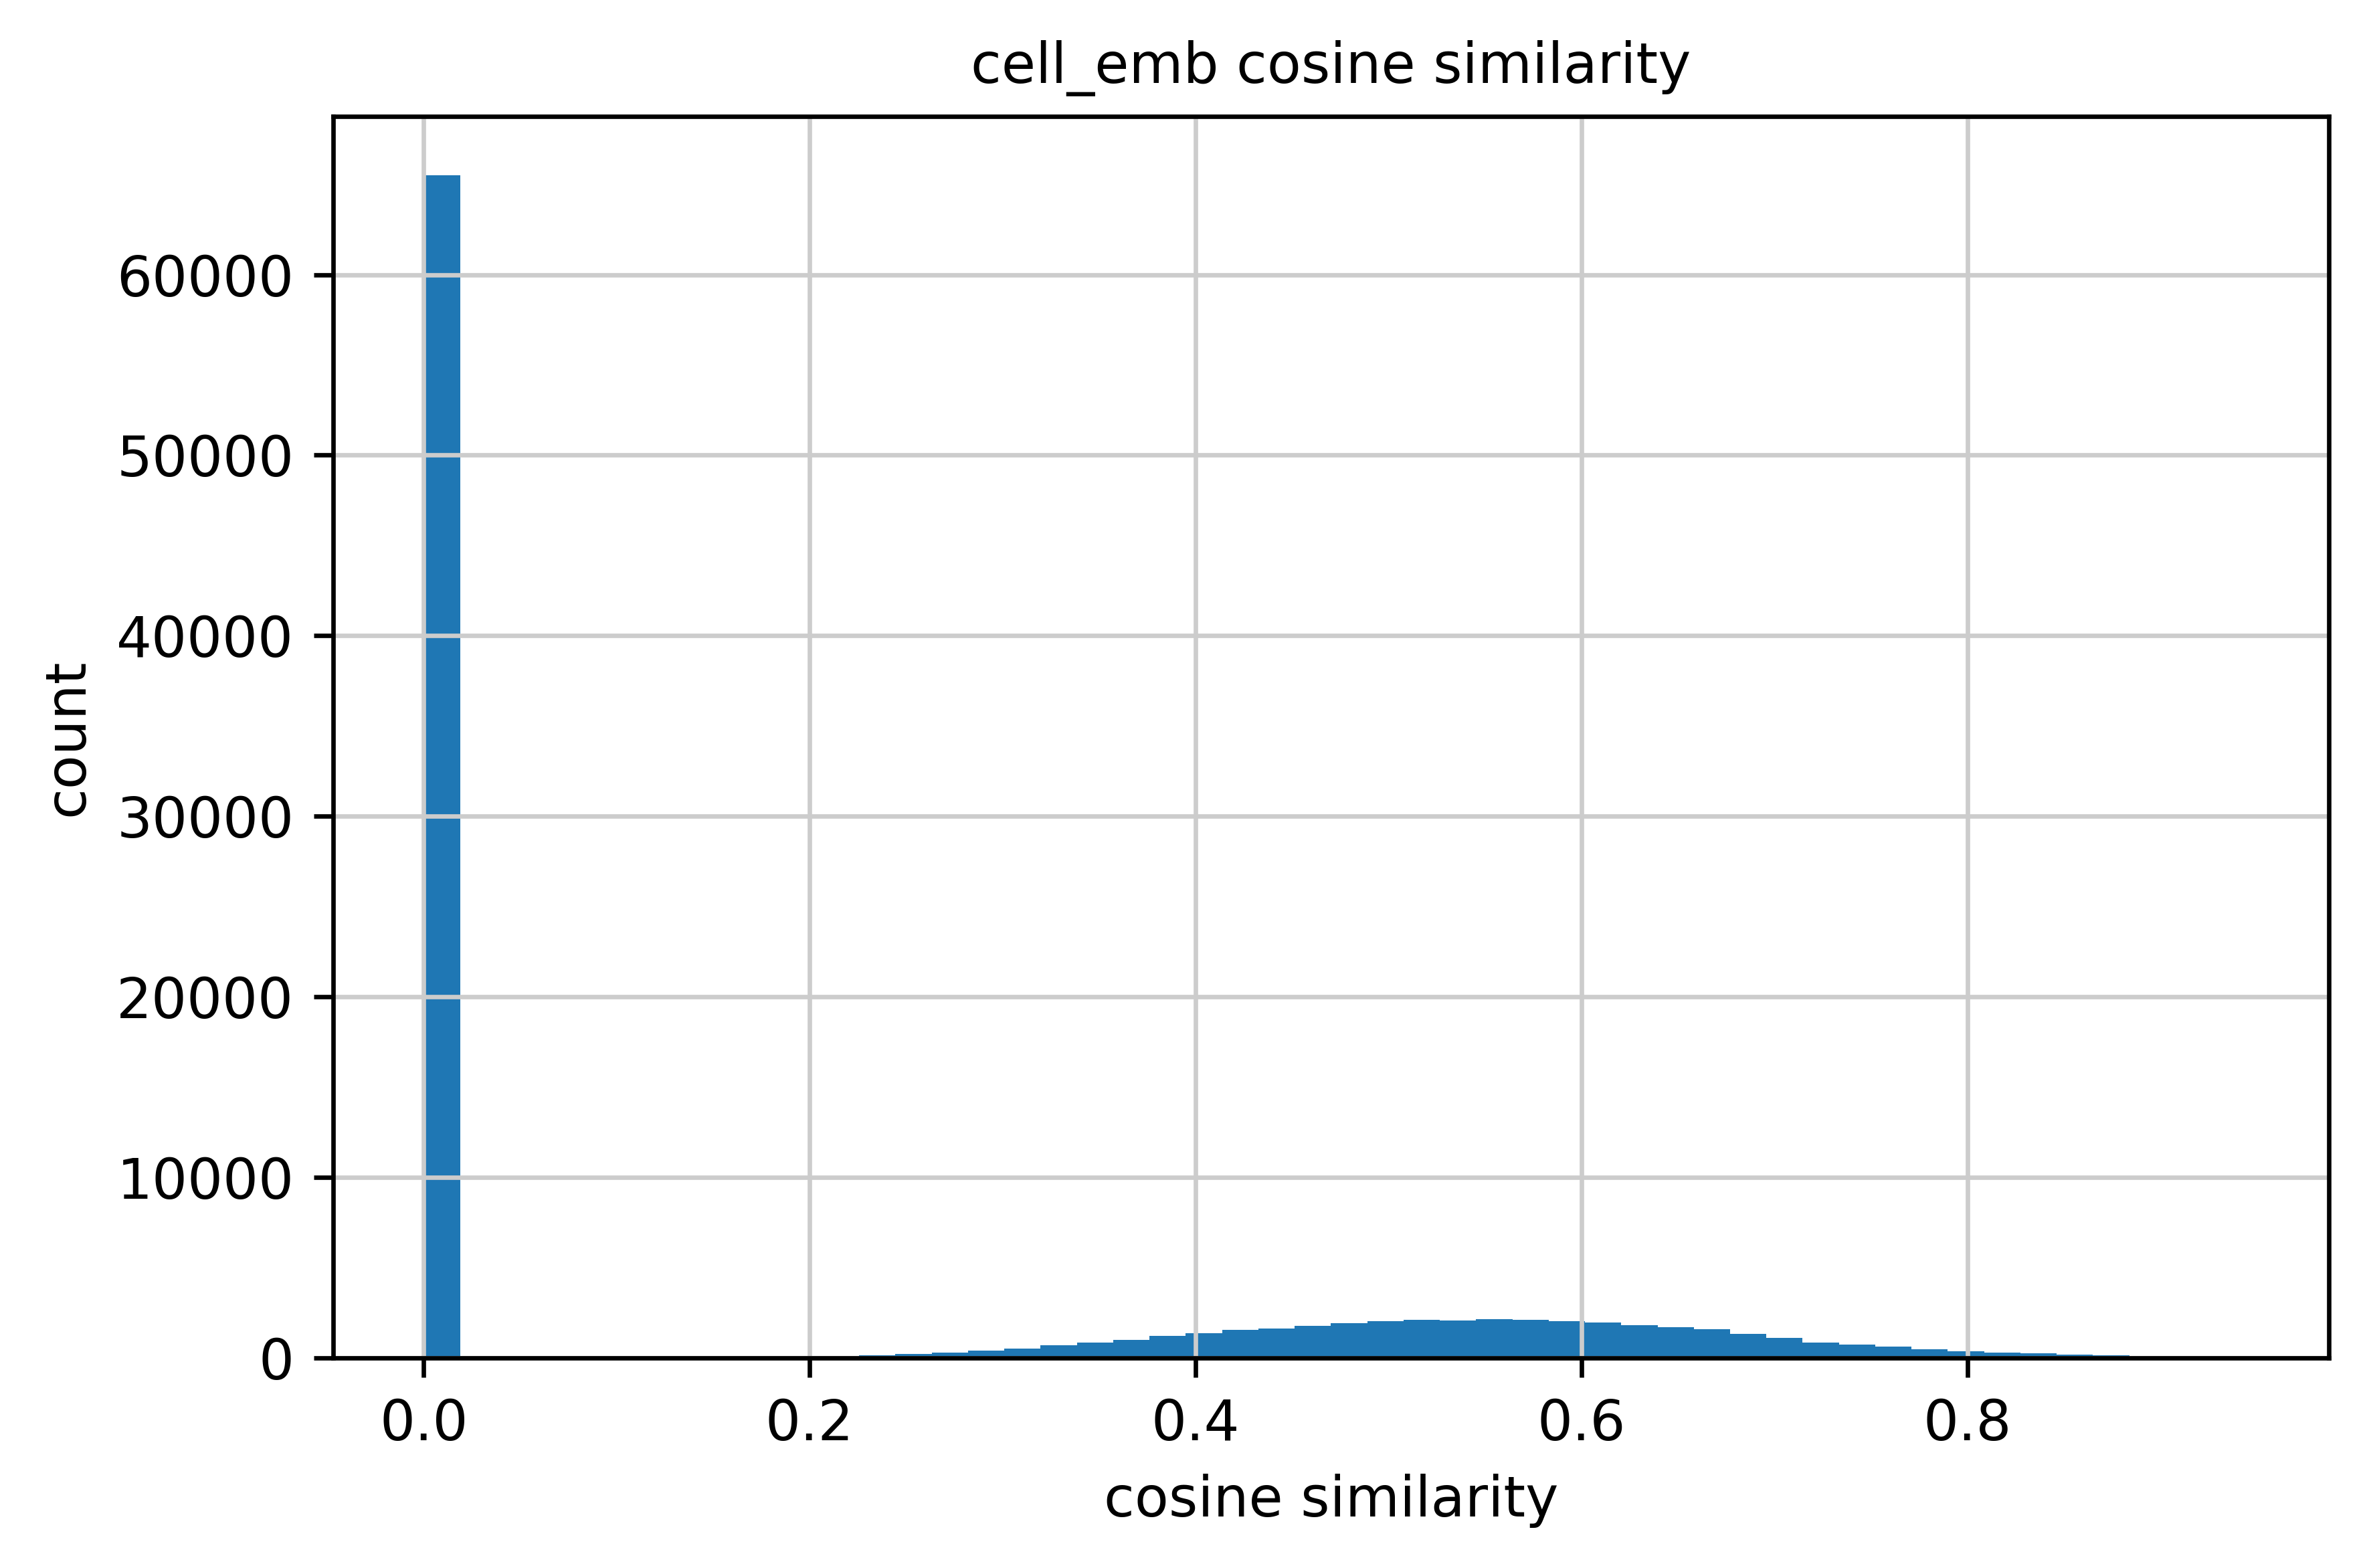

spatial_cell_emb (nonzero): mean=0.566452  min=-0.034081


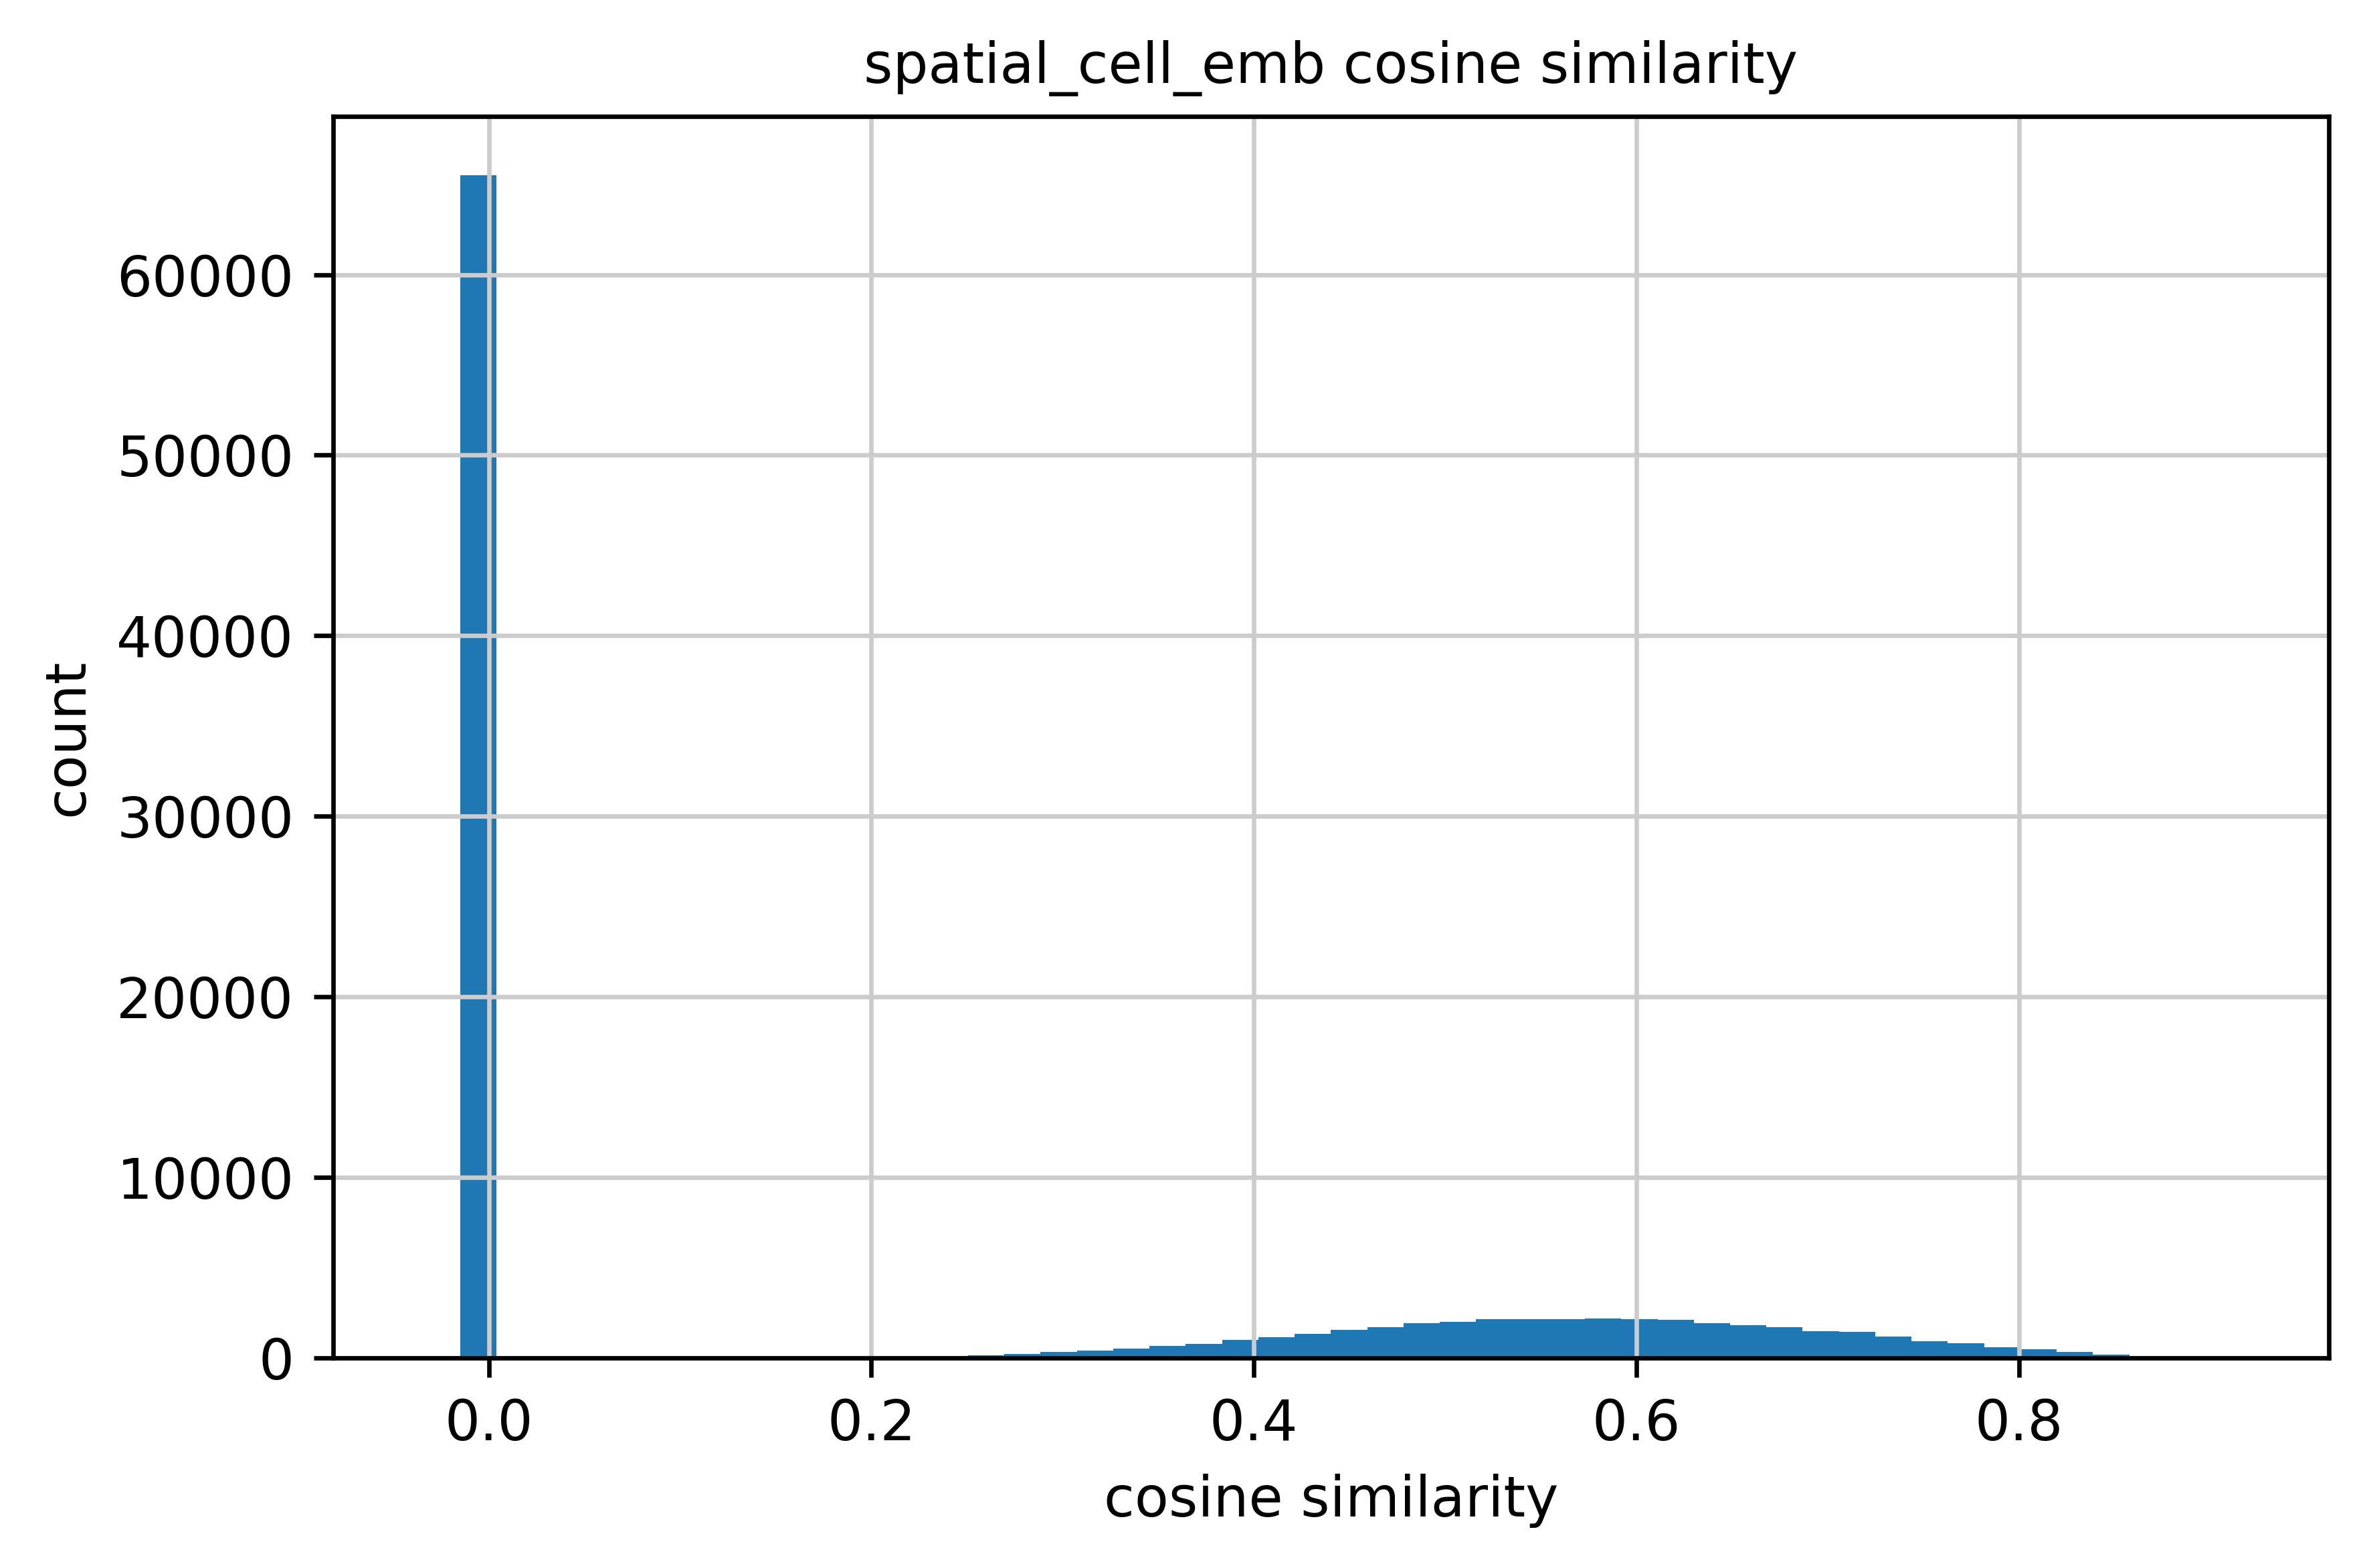

neighborhood_emb (nonzero): mean=0.661667  min=0.201524


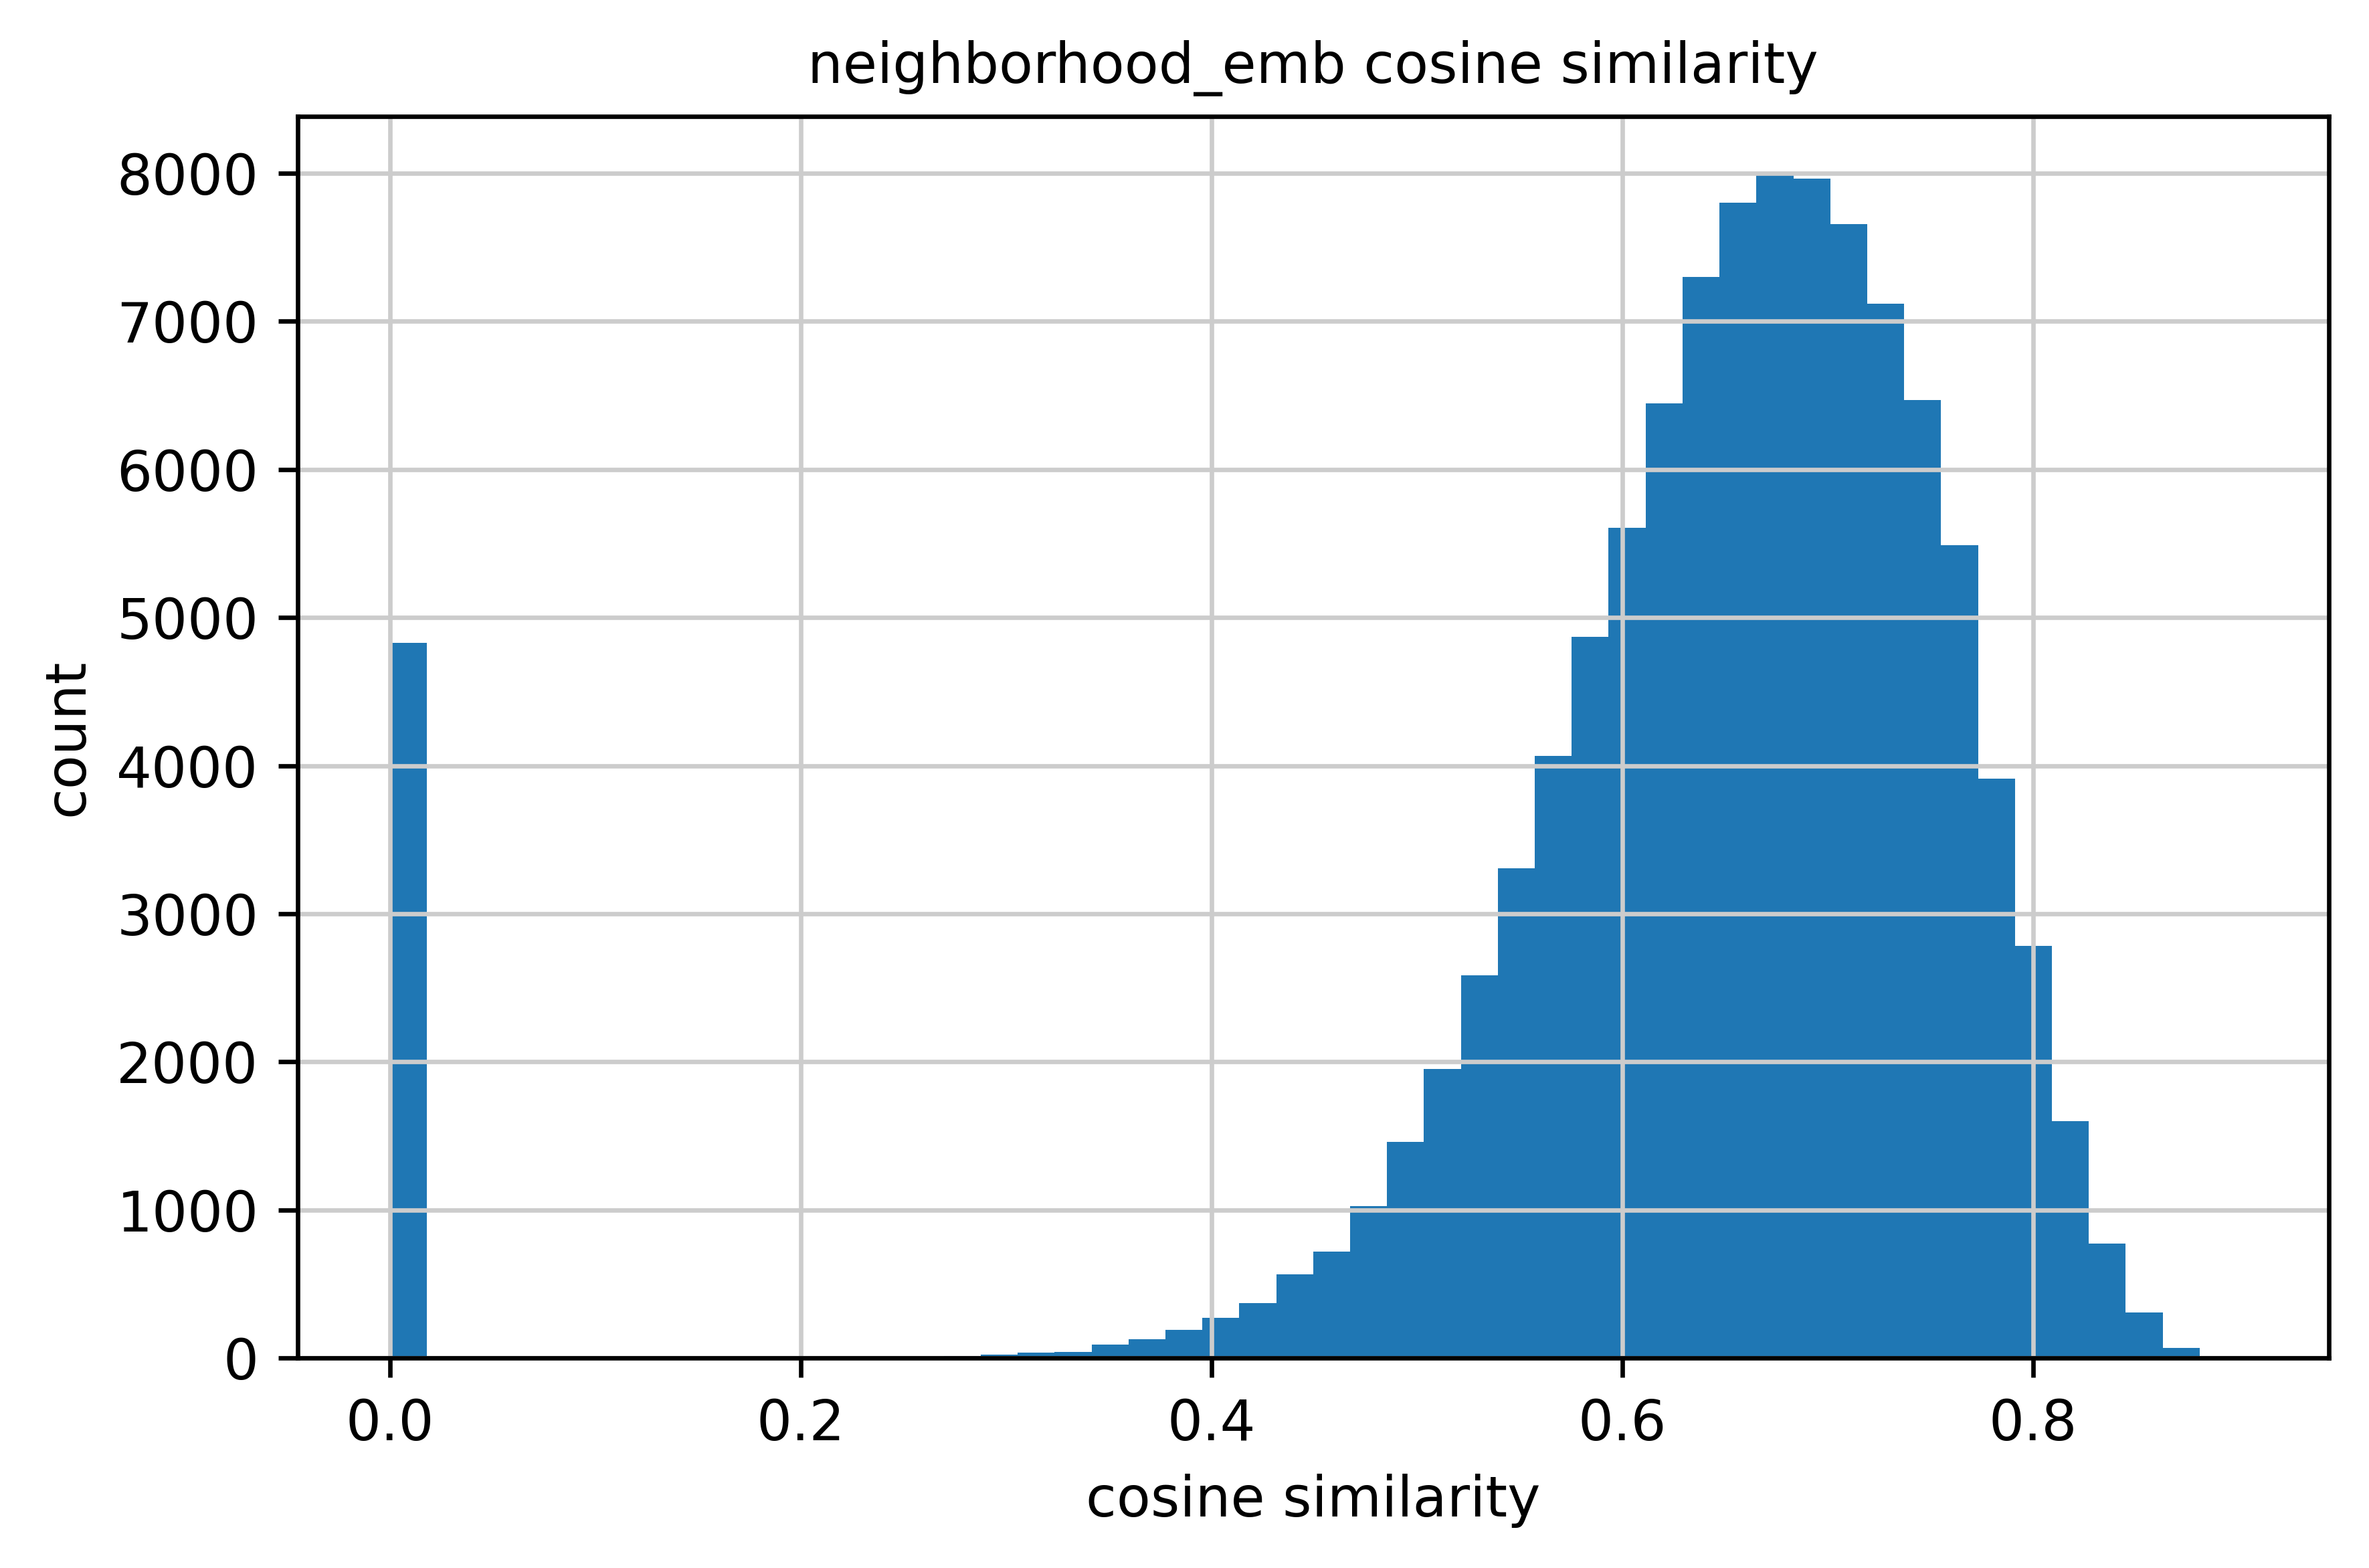

In [57]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    ignore_zeros=True
)

In [61]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
    ignore_zeros=True
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Plasmacytoid dendritic cell,1,0.246398,0.371756,0.716212
1,Neuron,136,0.392248,0.476357,0.634155
2,Basophil / Mast cell,7,0.422383,0.504029,0.610809
3,Lymphatic endothelium,157,0.440254,0.479158,0.595240
4,Memory B cell,78,0.449047,0.498525,0.632706
5,CD14+ monocyte,17,0.451692,0.510087,0.635779
6,Conventional dendritic cell,319,0.458018,0.516437,0.647465
7,Descending thin limb,876,0.469698,0.478654,0.607200
8,Neutrophil,189,0.475861,0.525316,0.651333
9,Natural killer cell,19,0.477606,0.555108,0.663359


In [62]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
    ignore_zeros=True
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Proximal nephron neighborhood,31806,0.502670,0.528821,0.657909
1,Loop of Henle neighborhood,9744,0.521212,0.544520,0.678022
2,Injured proximal nephron neighborhood,3539,0.525827,0.506633,0.657351
3,Distal nephron neighborhood,21237,0.526118,0.521588,0.654127
4,Fibrovascular neighborhood,22052,0.530218,0.523562,0.629721
5,Glomerular neighborhood,17499,0.595087,0.653167,0.708587


In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.8.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

### 2.5.9 Perturbation Case 9 (PDGFRB Signaling Axis)

Knockout Perturbation:
- Cell & Neighborhood
    - PDGFRB (ENSG00000113721)
    - PDGFB (ENSG00000100311)
    - PDGFD (ENSG00000170962)
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 9
pert_genes = [
    'PDGFRB',
    'PDGFB',
    'PDGFD'
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.9.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.9.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.14 Perturbation Case 14

Knockout Perturbation:
- Cell & Neighborhood
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [74]:
pert_case = 14
pert_genes = [
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
]

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [75]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
perturbed_dataset[530383]

In [ ]:
adata_cell = adata[adata.obs['cell_id'] == 'CV6-KID-0-FT-5-S3_1007_batch24_47039-slice9']

In [ ]:
adata_cell.obsm

In [ ]:
cosine_sim_per_row(adata_cell.obsm['cell_emb'], adata_cell.obsm['cell_emb_perturb_case14'])

#### 2.5.8.14 Cell Perturbations

In [76]:
perturbed_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3', 'pert_flag_idx_4', 'pert_flag_idx_5', 'pert_flag_idx_6', 'pert_flag_idx_7', 'pert_flag_idx_8', 'pert_flag_idx_9', 'pert_flag_idx_10', 'pert_flag_idx_11', 'pert_flag_idx_12', 'pert_flag_idx_13', 'pert_flag_idx_14', 'pert_flag_idx_15', 'pert_flag_idx_16', 'pert_flag_idx_17', 'pert_flag_idx_18', 'pert_flag_idx_19', 'pert_flag_idx_20', 'pert_flag_idx_21', 'pert_flag_idx_22', 'pert_flag_idx_23', 'pert_flag_idx_24', 'pert_flag_idx_25', 'pert_flag_idx_26', 'pert_flag_idx_27', 'pert_flag_idx_28', 'pert_flag_idx_29', 'pert_flag_idx_30', 'pert_flag_idx_31', 'pert_flag_idx_32', 'pert_flag_idx_33', 'pert_flag_idx_34', 'pert_flag_idx_35', 'pert_flag_idx_36', 'pert_flag_idx_37', 'pert_flag_idx_38', 'pert_flag_idx_39', 'pert_flag_id

In [77]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

Filter: 100%|██████████| 973830/973830 [01:09<00:00, 14013.86 examples/s]


In [78]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

395248


In [79]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

cell_emb (nonzero): mean=0.998274  min=0.784618


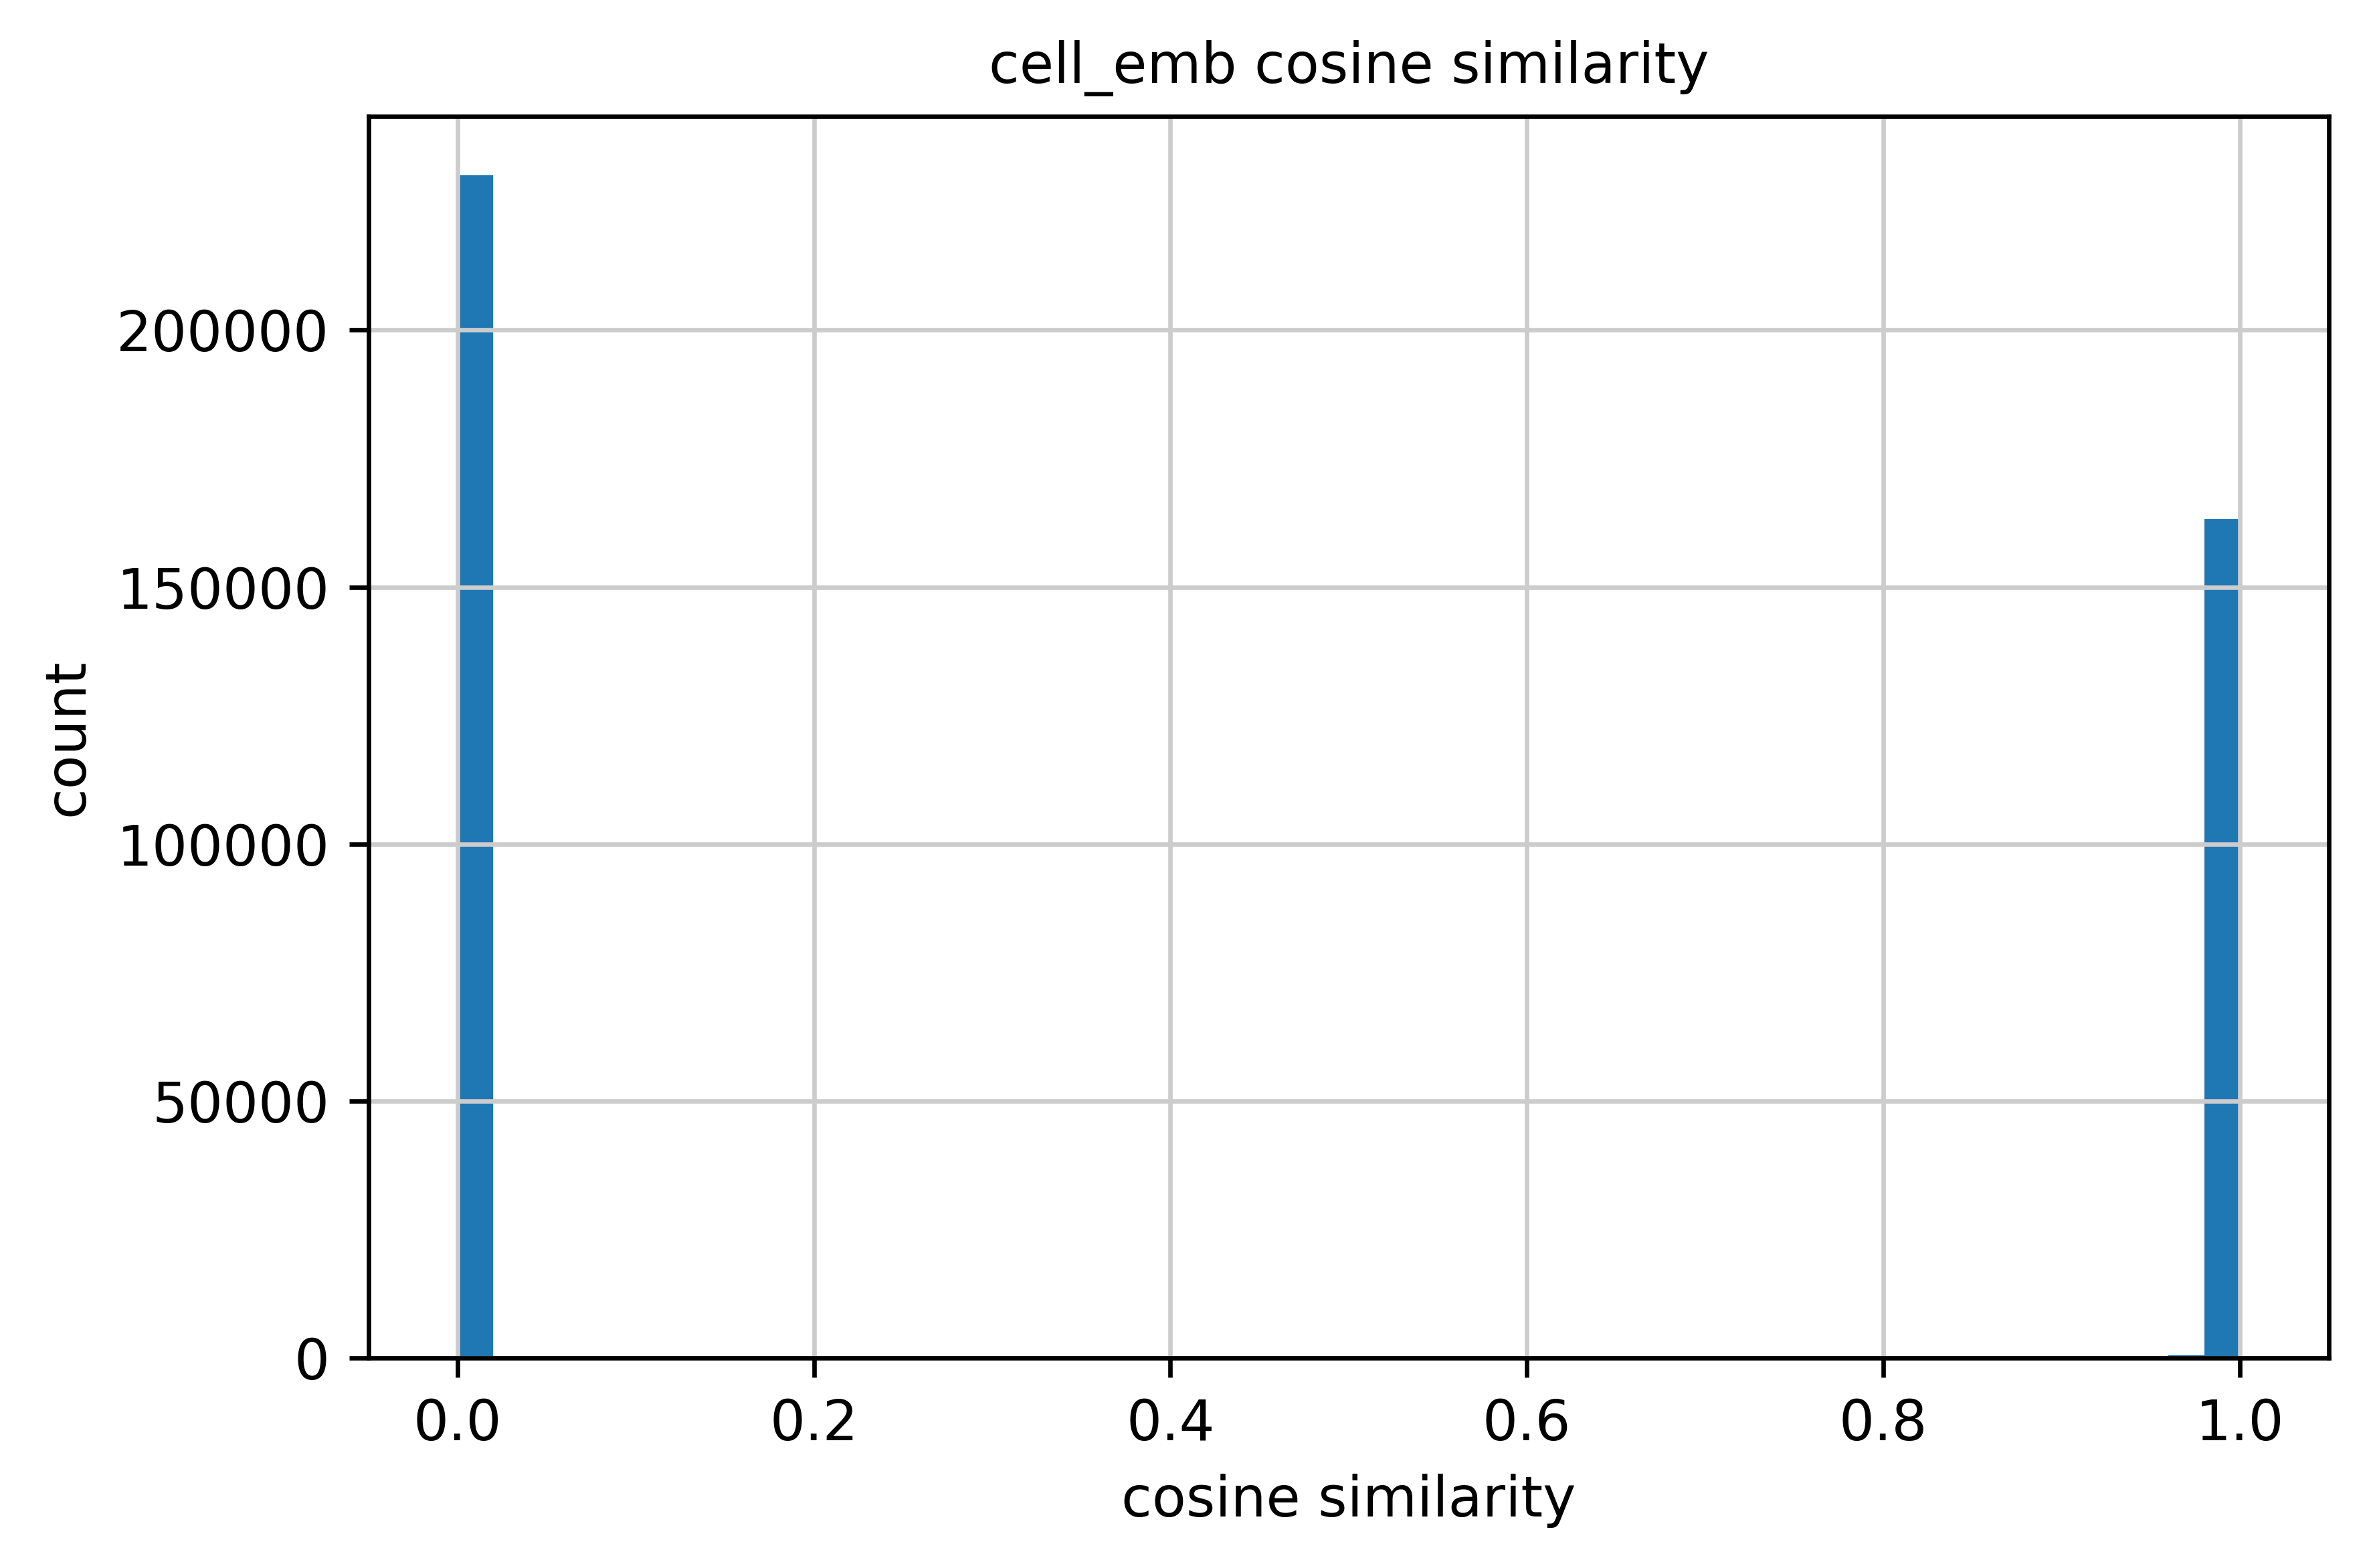

spatial_cell_emb (nonzero): mean=0.999056  min=0.810637


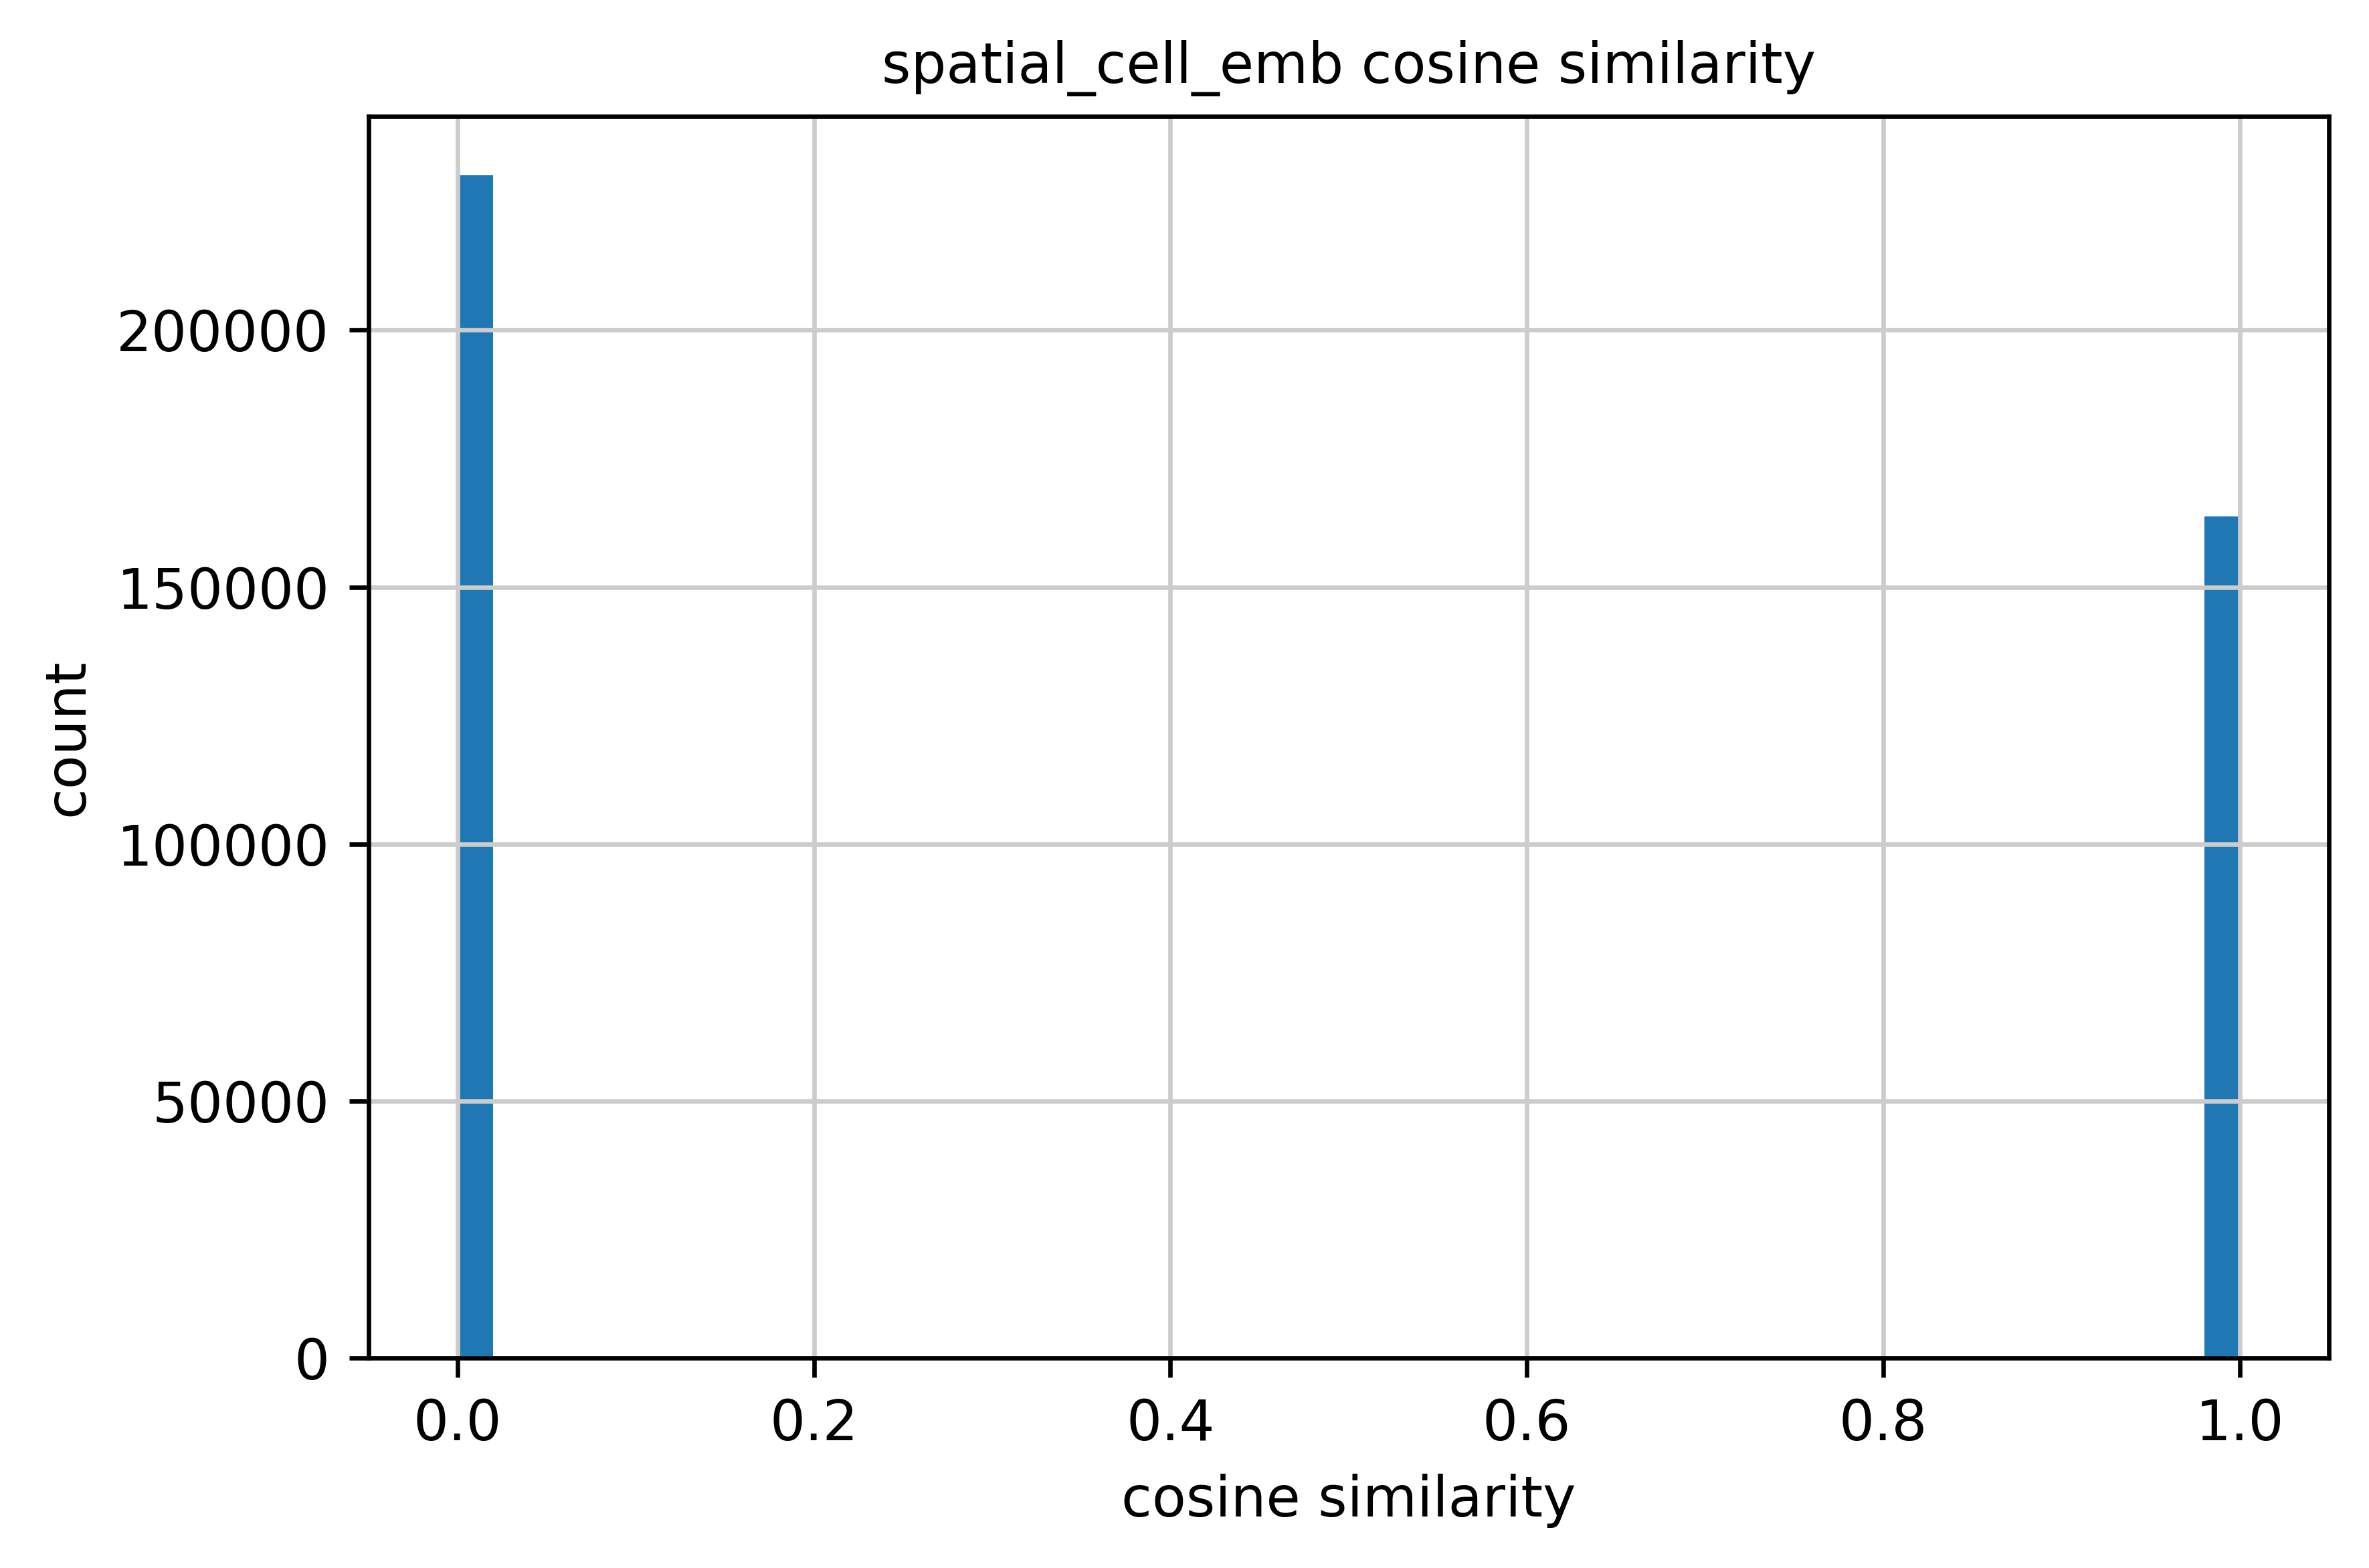

neighborhood_emb (nonzero): mean=0.999000  min=0.747730


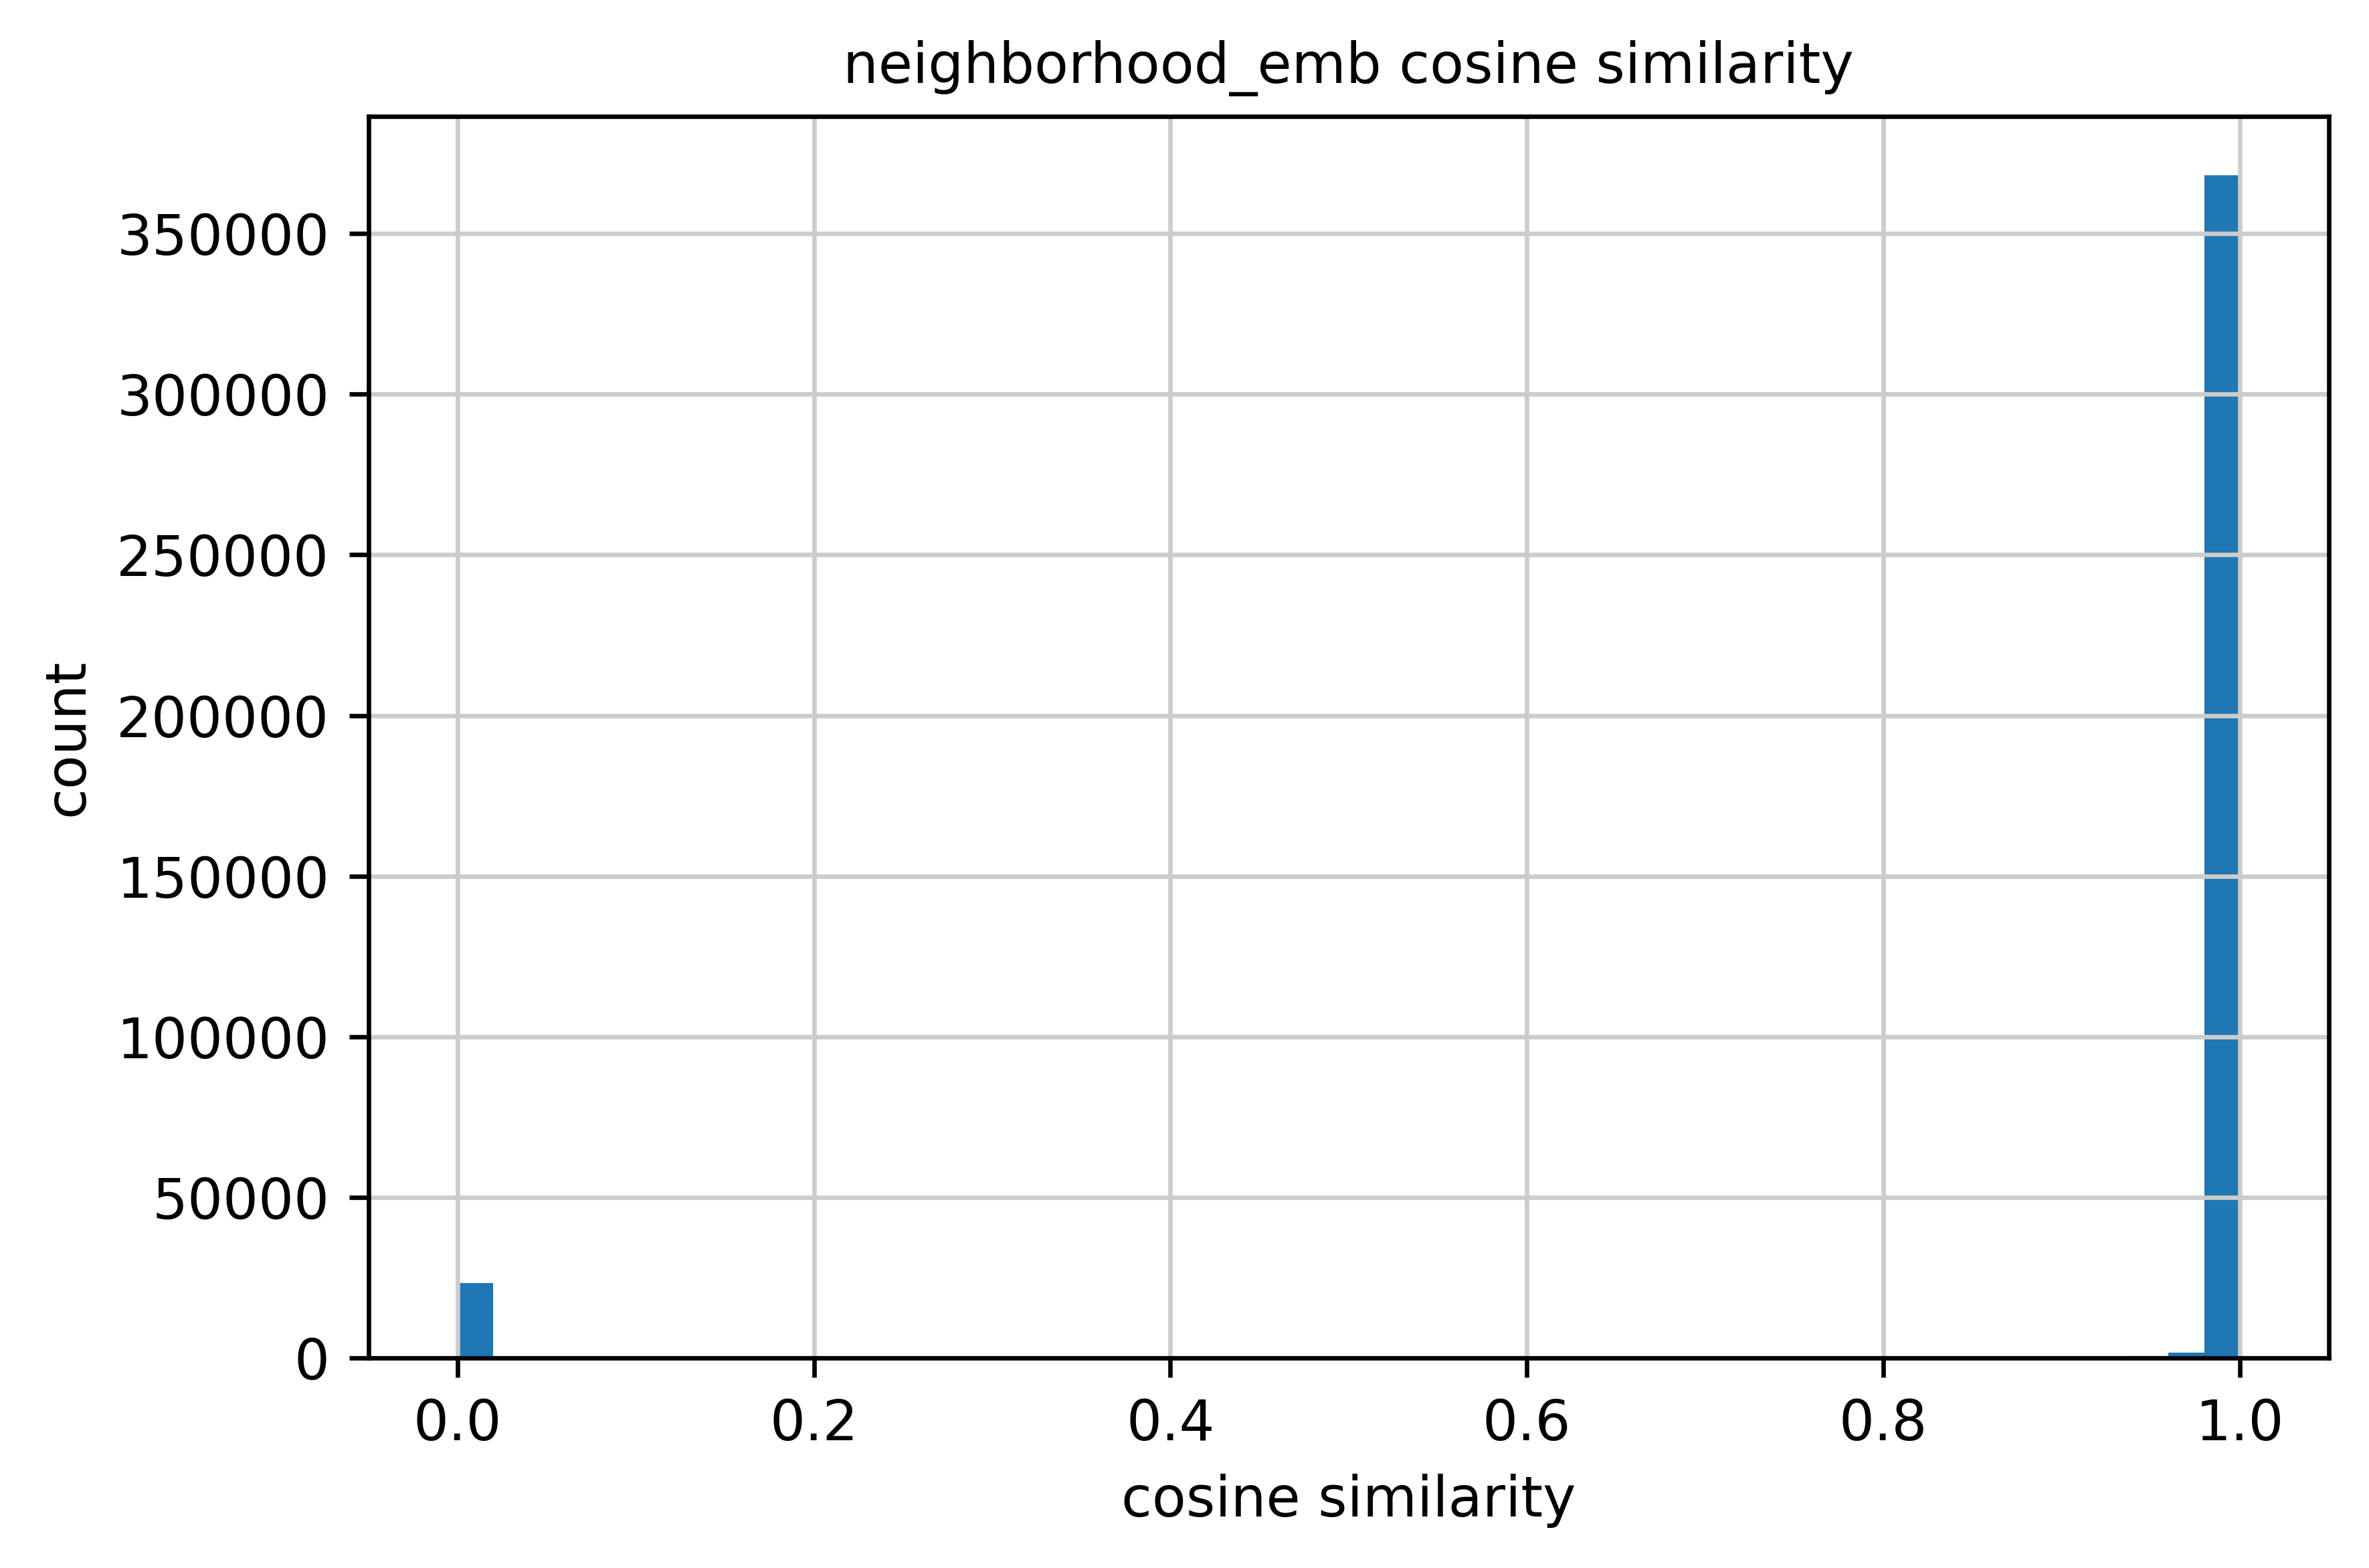

In [94]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    ignore_zeros=True
)

In [104]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
    ignore_zeros=True,
)
df_cos_sim_sorted_cell_type

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Natural killer cell,109,0.989061,0.994635,0.999209
1,Memory B cell,353,0.995097,0.997858,0.998527
2,Fibroblast,696,0.996281,0.998239,0.998760
3,Glomerular endothelial cell,25068,0.996405,0.997830,0.999030
4,Neuron,692,0.996701,0.998888,0.998496
5,CD16+ monocyte,35,0.996720,0.999856,0.999207
6,Peritubular capillary,35473,0.996884,0.997594,0.998484
7,Descending thin limb,2812,0.996900,0.998074,0.998711
8,CD8+ T cell,2704,0.997460,0.998740,0.999034
9,Mesangial cell,11501,0.998179,0.999671,0.999760


In [105]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb_glom_vasc_interface", f"cell_emb_perturb_case{pert_case}_glom_vasc_interface", "cell_emb"),
           ("spatial_cell_emb_glom_vasc_interface", f"spatial_cell_emb_perturb_case{pert_case}_glom_vasc_interface", "spatial_cell_emb"),
           ("neighborhood_emb_glom_vasc_interface", f"neighborhood_emb_perturb_case{pert_case}_glom_vasc_interface", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
    ignore_zeros=True
)
df_cos_sim_sorted_niche

,label,n_cells,cell_emb,spatial_cell_emb,neighborhood_emb
0,Loop of Henle neighborhood,40797,0.997838,0.998695,0.998570
1,Fibrovascular neighborhood,69252,0.998095,0.998745,0.998750
2,Injured proximal nephron neighborhood,9754,0.998170,0.998857,0.998971
3,Glomerular neighborhood,68840,0.998230,0.999357,0.999791
4,Proximal nephron neighborhood,125322,0.998280,0.999084,0.998897
5,Distal nephron neighborhood,81283,0.998699,0.998918,0.998870


In [106]:
print(f"Cell embedding average: {str(results['cell_emb'][results['cell_emb'] != 0].mean())}")
print(f"Spatial cell embedding average: {str(results['spatial_cell_emb'][results['spatial_cell_emb'] != 0].mean())}")
print(f"Neighborhood embedding average: {str(results['neighborhood_emb'][results['neighborhood_emb'] != 0].mean())}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

Cell embedding average: 0.99827373
Spatial cell embedding average: 0.99905634
Neighborhood embedding average: 0.99900025
Lowest cell embedding average per cell type: 0.9890609383583069
Lowest spatial cell embedding average per cell type: 0.9946346282958984
Lowest neighborhood embedding average per cell type: 0.9984843730926514
Lowest cell embedding average per niche: 0.9978378415107727
Lowest spatial cell embedding average per niche: 0.9986948370933533
Lowest neighborhood embedding average per niche: 0.998570442199707


#### 2.5.8.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted

### 2.5.9 Perturbation Case 16 (10% Random Genes)

Knockout Perturbation:
- Cell & Neighborhood
    - 10% Random Genes
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
random.seed(42)
all_genes = adata.var_names.tolist()
sampled_genes = random.sample(all_genes, k=len(all_genes)//10)

In [ ]:
pert_case = 16
pert_genes = sampled_genes
len(pert_genes)

In [ ]:
for gene in pert_genes:
    print(adata[:, adata.var_names.isin([gene])].var)

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

#### 2.5.9.1 Cell Perturbations

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

#### 2.5.9.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted_cell_type = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_cell_type

In [ ]:
df_cos_sim_sorted_niche = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted_niche

In [ ]:
print(f"Cell embedding average: {str(np.mean(results['cell_emb']))}")
print(f"Spatial cell embedding average: {str(np.mean(results['spatial_cell_emb']))}")
print(f"Neighborhood embedding average: {str(np.mean(results['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['cell_emb']))}")
print(f"Lowest spatial cell embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per cell type: {str(np.min(df_cos_sim_sorted_cell_type['neighborhood_emb']))}")
print("====================")
print(f"Lowest cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['cell_emb']))}")
print(f"Lowest spatial cell embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['spatial_cell_emb']))}")
print(f"Lowest neighborhood embedding average per niche: {str(np.min(df_cos_sim_sorted_niche['neighborhood_emb']))}")

### 2.5.14 Perturbation Case 16

Knockout Perturbation:
- Cell & Neighborhood
    'KDR',
    'VEGFA',
    'VEGFB',
    'FLT4',
    'VEGFC',
    'VEGFD',
    'PDGFRA',
    'PDGFA',
    'PDGFC',
    'PDGFRB',
    'PDGFB',
    'PDGFD',
    'KIT',
    'KITLG',
    'FLT3',
    'FLT3LG',
    'RET',
    'GDNF',
    'CSF1R',
    'CSF1',
    'IL34',
- Apply to pre-treatment samples (data source 'DIAMOND')
- Compare with ?

In [ ]:
pert_case = 16

In [ ]:
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case{pert_case}")

In [ ]:
adata_cell = adata[adata.obs['cell_id'] == 'CV6-KID-0-FT-5-S3_1007_batch24_47039-slice9']

In [ ]:
adata_cell.obsm

In [ ]:
cosine_sim_per_row(adata_cell.obsm['cell_emb'], adata_cell.obsm['cell_emb_perturb_case14'])

#### 2.5.8.14 Cell Perturbations

In [ ]:
perturbed_dataset

In [ ]:
# Filter for cell perturbations
pert_flag_even_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
    and int(name.split("_")[-1]) % 2 == 0
]

cell_pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_even_cols)
)

In [ ]:
cell_pert_cell_ids = list(cell_pert_filtered_dataset['cell_id'])
print(len(cell_pert_cell_ids))

In [ ]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="cell_emb",
    ascending=True,
)
df_cos_sim_sorted

#### 2.5.8.2 Neighborhood Perturbations

In [ ]:
# Filter for all perturbations
pert_flag_cols = [
    name
    for name in perturbed_dataset.features
    if name.startswith("pert_flag_idx_")
]

pert_filtered_dataset = perturbed_dataset.filter(
    lambda x: any(x[col] for col in pert_flag_cols)
)

In [ ]:
pert_cell_ids = list(pert_filtered_dataset['cell_id'])
print(len(pert_cell_ids))

In [ ]:
adata_sub_pert = adata[adata.obs_names.isin(pert_cell_ids)]

In [ ]:
results, summary = analyze_embedding_cos_sims(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")]
)

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=cell_type_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted

In [ ]:
df_cos_sim_sorted = summarize_cosine_sim_by_label(
    adata_sub_cell_pert,
    pairs=[("cell_emb", f"cell_emb_perturb_case{pert_case}", "cell_emb"),
           ("spatial_cell_emb", f"spatial_cell_emb_perturb_case{pert_case}", "spatial_cell_emb"),
           ("neighborhood_emb", f"neighborhood_emb_perturb_case{pert_case}", "neighborhood_emb")],
    label_key=niche_key,
    agg="mean",
    sort_by="neighborhood_emb",
    ascending=True,
)
df_cos_sim_sorted

## 2.6 Decode Counts

In [ ]:
import anndata as ad
from app.count_decoder import apply_count_decoder
from app.count_decoder import _spot_level_metrics, _apply_metric_transform, _to_dense
import numpy as np

adata_path = "/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation/nemokidneyxeniumatlas_annotated_processed.h5ad"
checkpoint_path = "results/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key = "cell_emb"
checkpoint_path = "results_neb/zinb_decoder.pt"  # or a folder with zinb_decoder.pt inside
emb_key="neighborhood_emb"

adata = ad.read_h5ad(adata_path)

adata = apply_count_decoder(
    adata,
    emb_key=emb_key,
    model_folder_path=checkpoint_path,  # can be folder or exact file
    decoded_counts_layer_key="decoded_counts",
    # optional overrides:
    # loss_type="nb_softplus",
    # device=0,
    # batch_size=1024,
)
 
preds = _to_dense(adata.layers["decoded_counts"])
target = _to_dense(adata.layers["counts"])
target = _to_dense(adata.layers["counts_neighborhood"])

# optional: same transform used in training metrics
preds = _apply_metric_transform(preds, "none")  # or "log1p"
target = _apply_metric_transform(target, "none")

spot_metrics = _spot_level_metrics(preds, target)
print(spot_metrics)

adata.write_h5ad("/path/to/output_with_decoded_counts.h5ad")

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_neighborhood')

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_cell'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='neighborhood_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results_neb/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_neighborhood_case1'

In [ ]:
adata = apply_count_decoder(
    adata,
    emb_key='cell_emb_perturb_case1',
    model_folder_path='/nfs/team361/mv10/nemo_v6/nichejepa/results/zinb_decoder.pt',
    decoded_counts_layer_key='dec_counts_perturbed_cell_case1'

In [ ]:
adata.write(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [ ]:
diff testing dec_counts_neighborhood <-> dec_counts_perturbed_neighborhood

In [ ]:
# adata.obsm[emb_key] -> adata.layers[decoded_counts_layer_key]

In [ ]:
perturb_df = perturb_df.head(3)

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

In [ ]:
thresh = 0.99
for i, gene in enumerate(pert_genes):
    cell_pert_indices = [i*2]
    
    filtered_dataset = perturbed_dataset.filter(
        lambda x: any(x[f"pert_flag_idx_{i}"] for i in cell_pert_indices)
    )
    
    cell_pert_cell_ids = list(filtered_dataset['cell_id'])
    
    adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]
    
    A = adata_sub_cell_pert.obsm['cell_emb']
    B = adata_sub_cell_pert.obsm['cell_emb_perturb_case2']
    
    A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)
    
    cos_sim = np.sum(A_norm * B_norm, axis=1)
    print(f"Gene: {gene}")
    print(f"Mean cosine similarity: {np.mean(cos_sim)}")
    print(f"Min cosine similarity: {np.min(cos_sim)}")
    print(f"Smaller than {thresh}: {int((cos_sim < thresh).sum())}/{cos_sim.shape[0]}")